# Pronunciation Assessment Model (SpeechOcean762) — Enhanced Training & Thesis Evaluation

**Setup on Kaggle:**
1. **Add Data:** `tnguynthnh142/speechocean762`
2. **Settings:** Accelerator `GPU T4` + `Internet ON`
3. **Run All**

**Upgrades in this version:**
- **LoRA Coverage Expansion:** Adapts all 6 WavLM transformer linear projections (`q_proj`, `k_proj`, `v_proj`, `out_proj`, `intermediate_dense`, `output_dense`, keeping `r=8, lora_alpha=16` for 100% plug-and-play compatibility with `infer/pronunciation.py`).
- **Speaker-Disjoint Train/Val Split + Isolated Test Set:** Stratified 90/10 speaker-disjoint split inside official `train` for early stopping; official 2,500-utterance `test` set stays untouched until final evaluation.
- **Multi-Granularity Loss & Calibration:** Combines `MSE + SmoothL1`, batch-level Pearson Correlation (`PCC`) across utterance, word, AND phoneme granularities, plus auxiliary `CTC` alignment loss.
- **Regularization & EMA:** Train-only SNR-safe waveform augmentation, tuned WavLM `layerdrop=0.05` & short-span SpecAugment (`mask_time_length=4`), parameter-free feature channel masking, and `EMA (decay=0.998)` smoothing.
- **Speed & Efficiency:** Pre-cached `float16` RAM audio + length-bucketed batching + full `fp16` AMP during train/val/test.
- **Clean Output Artifacts:** Saves **only the single best checkpoint** (`/kaggle/working/best_model.pt`) and generates 4 high-DPI (300 DPI) thesis figures + CSV/JSON metrics in `/kaggle/working/reports_pronunciation/`.


In [1]:
!pip uninstall -y -q torchao
!pip install -q transformers torchaudio torch-geometric peft tqdm scipy scikit-learn pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 962.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.7 MB/s eta 0:00:00


In [2]:
# Bypass compatibility conflict between legacy torchao on Kaggle and recent PEFT
try:
    import peft.import_utils
    peft.import_utils.is_torchao_available = lambda: False
except Exception:
    pass

import json
import math
import os
import random
import re
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, Sampler
from tqdm import tqdm

CONFIG = {
    "wavlm": {
        "model_name": "microsoft/wavlm-large",
        "freeze": True,
        "use_lora": True,
        "lora_r": 8,
        "lora_alpha": 16,
        "lora_dropout": 0.10,
        "lora_target_modules": [
            "q_proj",
            "k_proj",
            "v_proj",
            "out_proj",
            "intermediate_dense",
            "output_dense",
        ],
        "layerdrop": 0.05,
        "mask_time_prob": 0.05,
        "mask_time_length": 4,
        "mask_time_min_masks": 1,
        "mask_feature_prob": 0.0,
        "mask_feature_length": 16,
    },
    "transformer": {
        "num_layers": 3,
        "num_heads": 8,
        "ff_dim": 2048,
        "dropout": 0.25,
        "max_seq_len": 800,
    },
    "ctc_align": {"use_wavlm_ctc_head": True},
    "phoneme_graph": {
        "hidden_dim": 256,
        "num_gat_layers": 2,
        "num_heads": 4,
        "dropout": 0.20,
        "edge_types": {"sequential": True, "same_word": True, "same_syllable": False},
    },
    "multitask": {
        "hidden_dim": 256,
        "dropout": 0.25,
        "score_scale": 2.0,
        "utterance_aspects": ["accuracy", "fluency", "completeness", "prosodic", "total"],
        "word_aspects": ["accuracy", "stress", "total"],
        "phoneme_aspects": ["accuracy"],
    },
    "paths": {
        "best_checkpoint": "/kaggle/working/best_model.pt",
        "report_dir": "/kaggle/working/reports_pronunciation",
    },
    "train": {
        "seed": 42,
        "batch_size": 4,
        "grad_accum_steps": 4,
        "num_epochs": 28,
        "learning_rate": 1.5e-4,
        "learning_rate_wavlm": 4.0e-5,
        "weight_decay": 0.03,
        "warmup_epochs": 2,
        "early_stopping_patience": 6,
        "pcc_weight": 0.45,
        "word_pcc_weight": 0.35,
        "phone_pcc_weight": 0.35,
        "ctc_weight": 0.15,
        "ema_decay": 0.998,
        "feature_dropout_p": 0.10,
        "val_ratio": 0.10,
        "cache_audio_in_ram": True,
        "max_ram_cache_mb": 2048,
        "augment_train": True,
        "grad_clip": 1.0,
        "num_workers": 0,
        "pin_memory": True,
        "use_amp": True,
        "save_every_epochs": 0,
        "loss_weights": {"utterance": 1.3, "word": 1.0, "phoneme": 0.9},
        "dataset": {
            "data_dir": None,
            "train_split": "train",
            "test_split": "test",
            "max_duration_sec": 8.0,
            "sample_rate": 16000,
        },
    },
}


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


KAGGLE_DATA_ROOT = Path("/kaggle/input/datasets/tnguynthnh142/speechocean762/speechocean762")
FALLBACK_ROOTS = (
    KAGGLE_DATA_ROOT,
    Path("/kaggle/input/speechocean762/speechocean762"),
    Path("/kaggle/input/speechocean762"),
)


def is_speechocean762_root(root: Path) -> bool:
    root = Path(root)
    return (
        (root / "train" / "wav.scp").is_file()
        and (root / "test" / "wav.scp").is_file()
        and ((root / "resource" / "scores.json").is_file() or (root / "scores.json").is_file())
    )


def find_speechocean762_dir(input_root: Optional[str] = None) -> Path:
    override = os.environ.get("KAGGLE_DATA_DIR")
    if override:
        root = Path(override)
        if is_speechocean762_root(root):
            return root
        raise FileNotFoundError(f"Invalid KAGGLE_DATA_DIR: {root}")

    for p in FALLBACK_ROOTS:
        if is_speechocean762_root(p):
            return p

    base = Path(input_root or "/kaggle/input")
    if base.is_dir():
        for wav_scp in base.rglob("wav.scp"):
            if wav_scp.parent.name == "train":
                root = wav_scp.parent.parent
                if is_speechocean762_root(root):
                    return root

    raise FileNotFoundError(
        "Dataset not found. Add Data: tnguynthnh142/speechocean762\n"
        f"Expected e.g. {KAGGLE_DATA_ROOT}"
    )


def verify_speechocean762(root: Path) -> Tuple[bool, List[str], dict]:
    root = Path(root)
    issues: List[str] = []
    info = {"root": str(root)}

    if not is_speechocean762_root(root):
        return False, ["Invalid dataset root"], info

    scores_p = root / "resource" / "scores.json"
    if not scores_p.is_file():
        scores_p = root / "scores.json"
    with open(scores_p, encoding="utf-8") as f:
        meta = json.load(f)
    info["scores"] = len(meta)

    if not (root / "WAVE").is_dir():
        issues.append("Missing WAVE/")

    with open(root / "train" / "wav.scp", encoding="utf-8") as f:
        uid, rel = f.readline().split(maxsplit=1)
        wav = root / rel.strip()
        if uid not in meta:
            issues.append("scores.json mismatch wav.scp")
        elif not wav.is_file():
            issues.append(f"Missing audio: {wav}")

    return not issues, issues, info


def _resolve_scores_path(root: Path) -> Path:
    for path in (root / "scores.json", root / "resource" / "scores.json"):
        if path.exists():
            return path
    raise FileNotFoundError(f"Missing scores.json under {root}")


def _load_utt2spk(split_dir: Path) -> Dict[str, str]:
    utt2spk = {}
    p = split_dir / "utt2spk"
    if p.is_file():
        with open(p, encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 2:
                    utt2spk[parts[0]] = parts[1]
    return utt2spk


def _extract_speaker(uid: str, wav_path: str, utt2spk: Dict[str, str]) -> str:
    if uid in utt2spk:
        return utt2spk[uid]
    m = re.search(r"(SPEAKER\d+)", wav_path, re.IGNORECASE)
    if m:
        return m.group(1).upper()
    return uid[:5] if len(uid) >= 5 else uid


def load_speechocean762(split: str = "train", data_dir: Optional[str] = None) -> List[Dict[str, Any]]:
    root = Path(data_dir)
    if not root.exists():
        raise FileNotFoundError(f"Dataset not found: {root.resolve()}")

    with open(_resolve_scores_path(root), encoding="utf-8") as f:
        scores = json.load(f)

    wav_scp = root / split / "wav.scp"
    if not wav_scp.exists():
        raise FileNotFoundError(f"Missing {wav_scp}")
    utt2spk = _load_utt2spk(root / split)

    samples = []
    with open(wav_scp, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            uid, path = line.split(maxsplit=1)
            if uid not in scores:
                continue
            wav_path = Path(path)
            if not wav_path.is_absolute():
                wav_path = (root / path).resolve()
            meta = scores[uid]
            samples.append({
                "id": uid,
                "speaker": _extract_speaker(uid, str(wav_path), utt2spk),
                "audio": str(wav_path),
                "text": meta["text"],
                "accuracy": meta.get("accuracy"),
                "fluency": meta.get("fluency"),
                "completeness": meta.get("completeness"),
                "prosodic": meta.get("prosodic"),
                "total": meta.get("total"),
                "words": meta.get("words", []),
            })
    return samples


def split_train_val_by_speaker(
    samples: List[Dict[str, Any]], val_ratio: float = 0.10, seed: int = 42
) -> Tuple[List[Dict[str, Any]], List[Dict[str, Any]], Dict[str, Any]]:
    """Stratified speaker-disjoint split inside official SpeechOcean train set."""
    spk_groups: Dict[str, List[Dict[str, Any]]] = {}
    for s in samples:
        spk_groups.setdefault(s["speaker"], []).append(s)

    unique_spks = sorted(spk_groups.keys())
    if len(unique_spks) < 5 or val_ratio <= 0.0:
        rng = random.Random(seed)
        idx = list(range(len(samples)))
        rng.shuffle(idx)
        n_val = max(1, int(round(len(samples) * val_ratio)))
        val_set = set(idx[:n_val])
        tr = [samples[i] for i in range(len(samples)) if i not in val_set]
        va = [samples[i] for i in range(len(samples)) if i in val_set]
        return tr, va, {"strategy": "utterance_fallback", "train_spk": len(unique_spks), "val_spk": len(unique_spks)}

    # Sort speakers by mean total score -> stratified uniform sampling across proficiency tiers
    spk_stats = []
    for spk in unique_spks:
        totals = [float(x["total"]) for x in spk_groups[spk] if x.get("total") is not None]
        mean_t = float(np.mean(totals)) if totals else 5.0
        spk_stats.append((mean_t, spk))
    spk_stats.sort(key=lambda t: (t[0], t[1]))

    n_val_spk = max(2, int(round(len(spk_stats) * val_ratio)))
    step = len(spk_stats) / float(n_val_spk)
    rng = random.Random(seed)
    val_spks = set()
    for k in range(n_val_spk):
        lo = int(math.floor(k * step))
        hi = max(lo + 1, int(math.floor((k + 1) * step)))
        chosen_idx = rng.randrange(lo, min(hi, len(spk_stats)))
        val_spks.add(spk_stats[chosen_idx][1])

    tr = [s for s in samples if s["speaker"] not in val_spks]
    va = [s for s in samples if s["speaker"] in val_spks]
    return tr, va, {
        "strategy": "speaker_disjoint_stratified",
        "train_spk": len(unique_spks) - len(val_spks),
        "val_spk": len(val_spks),
    }


def _read_wav_mono_16k(wav_path: str, sample_rate: int, max_samples: int) -> torch.Tensor:
    import torchaudio

    try:
        import soundfile as sf
        data, sr = sf.read(wav_path, dtype="float32")
        wav = torch.from_numpy(data)
        if wav.dim() > 1:
            wav = wav.mean(dim=-1)
    except Exception:
        wav, sr = torchaudio.load(wav_path)
        wav = wav.mean(dim=0)

    if int(sr) != int(sample_rate):
        wav = torchaudio.functional.resample(wav, int(sr), int(sample_rate))
    wav = wav.contiguous()
    if wav.shape[0] > max_samples:
        wav = wav[:max_samples]
    return wav


def _augment_waveform_train(wav: torch.Tensor) -> torch.Tensor:
    """Timing-preserving waveform augmentation aligned with inference preprocessing."""
    wav = wav.clone()
    if wav.numel() == 0:
        return wav
    # Remove DC offset
    wav = wav - wav.mean()
    r = random.random()
    if r < 0.35:
        # Match production peak_normalize(0.95) distribution with slight variation
        peak = wav.abs().max().clamp(min=1e-6)
        target_peak = random.uniform(0.75, 0.98)
        wav = wav * (target_peak / peak)
    elif r < 0.80:
        # Random gain jitter
        wav = wav * random.uniform(0.65, 1.30)

    # Light SNR-safe background Gaussian noise (28-45 dB SNR)
    if random.random() < 0.45:
        rms = wav.pow(2).mean().sqrt().clamp(min=1e-4)
        snr_db = random.uniform(28.0, 45.0)
        noise_std = float(rms) * (10.0 ** (-snr_db / 20.0))
        wav = wav + torch.randn_like(wav) * noise_std
    return wav.clamp(-1.0, 1.0)


class SpeechOcean762Dataset(Dataset):
    UTTERANCE_KEYS = ["accuracy", "fluency", "completeness", "prosodic", "total"]
    WORD_KEYS = ["accuracy", "stress", "total"]

    def __init__(
        self,
        samples: List[Dict[str, Any]],
        sample_rate: int = 16000,
        max_duration_sec: float = 8.0,
        score_scale: float = 5.0,
        augment: bool = False,
        cache_audio: bool = True,
        max_ram_cache_mb: int = 2048,
        name: str = "split",
    ):
        self.sample_rate = sample_rate
        self.max_samples = int(max_duration_sec * sample_rate)
        self.score_scale = score_scale
        self.augment = augment
        self.samples = samples
        self._audio_cache: Optional[List[torch.Tensor]] = None
        self.lengths: List[int] = []

        if cache_audio and len(samples) > 0:
            cached: List[torch.Tensor] = []
            bytes_used = 0
            max_bytes = int(max_ram_cache_mb * 1024 * 1024)
            for item in tqdm(samples, desc=f"Preloading audio ({name})", leave=False):
                w = _read_wav_mono_16k(item["audio"], self.sample_rate, self.max_samples)
                self.lengths.append(int(w.shape[0]))
                w_fp16 = w.to(torch.float16)
                bytes_used += w_fp16.numel() * 2
                if bytes_used <= max_bytes:
                    cached.append(w_fp16)
                else:
                    cached = []
                    break
            if len(cached) == len(samples):
                self._audio_cache = cached
                print(f"[{name}] Cached {len(cached)} waveforms in RAM ({bytes_used / (1024**2):.1f} MB, float16)")

        if len(self.lengths) != len(samples):
            self.lengths = [self.max_samples // 2] * len(samples)

    def __len__(self) -> int:
        return len(self.samples)

    def _get_waveform(self, idx: int) -> torch.Tensor:
        if self._audio_cache is not None:
            wav = self._audio_cache[idx].float()
        else:
            wav = _read_wav_mono_16k(self.samples[idx]["audio"], self.sample_rate, self.max_samples).float()
        if self.augment:
            wav = _augment_waveform_train(wav)
        return wav

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        item = self.samples[idx]
        words = item.get("words", [])
        phoneme_labels, word_labels = [], []
        phoneme_tokens, word_texts, word_phone_ranges = [], [], []

        for w in words:
            phones = w.get("phones", [])
            if isinstance(phones, str):
                phones = phones.split()
            pa = w.get("phones-accuracy", w.get("phones_accuracy", []))
            start = len(phoneme_tokens)
            phoneme_tokens.extend(phones)
            phoneme_labels.extend([float(x) for x in pa])
            word_phone_ranges.append((start, len(phoneme_tokens)))
            word_texts.append(w.get("text", ""))
            word_labels.append({k: float(w.get(k, 0)) / self.score_scale for k in self.WORD_KEYS})

        utterance_labels = {
            k: float(item.get(k, 0)) / self.score_scale
            for k in self.UTTERANCE_KEYS
            if item.get(k) is not None
        }
        if "completeness" not in utterance_labels:
            utterance_labels["completeness"] = utterance_labels.get("fluency", 0.0)

        wav = self._get_waveform(idx)
        return {
            "id": item["id"],
            "speaker": item.get("speaker", ""),
            "waveform": wav,
            "duration_sec": float(wav.shape[0]) / float(self.sample_rate),
            "text": item["text"],
            "phoneme_tokens": phoneme_tokens,
            "phoneme_labels": phoneme_labels,
            "word_labels": word_labels,
            "word_texts": word_texts,
            "word_phone_ranges": word_phone_ranges,
            "utterance_labels": utterance_labels,
        }


class LengthBucketBatchSampler(Sampler[List[int]]):
    """Groups similar-duration clips per batch to minimize padding overhead & VRAM spikes."""

    def __init__(self, lengths: List[int], batch_size: int, shuffle: bool = True, noise_ratio: float = 0.15, seed: int = 42):
        self.lengths = lengths
        self.batch_size = max(1, int(batch_size))
        self.shuffle = shuffle
        self.noise_span = int(max(lengths, default=16000) * noise_ratio)
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1
        indices = list(range(len(self.lengths)))
        if self.shuffle:
            indices.sort(key=lambda i: self.lengths[i] + rng.uniform(-self.noise_span, self.noise_span))
            batches = [indices[i : i + self.batch_size] for i in range(0, len(indices), self.batch_size)]
            rng.shuffle(batches)
        else:
            indices.sort(key=lambda i: self.lengths[i])
            batches = [indices[i : i + self.batch_size] for i in range(0, len(indices), self.batch_size)]
        for b in batches:
            yield b

    def __len__(self) -> int:
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size


def collate_fn(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    waveforms = [b["waveform"] for b in batch]
    wav_lengths = torch.tensor([w.shape[0] for w in waveforms], dtype=torch.long)
    return {
        "ids": [b["id"] for b in batch],
        "speakers": [b["speaker"] for b in batch],
        "duration_secs": [b["duration_sec"] for b in batch],
        "waveforms": pad_sequence(waveforms, batch_first=True),
        "wav_lengths": wav_lengths,
        "texts": [b["text"] for b in batch],
        "phoneme_tokens": [b["phoneme_tokens"] for b in batch],
        "phoneme_labels": [b["phoneme_labels"] for b in batch],
        "word_labels": [b["word_labels"] for b in batch],
        "word_texts": [b["word_texts"] for b in batch],
        "word_phone_ranges": [b["word_phone_ranges"] for b in batch],
        "utterance_labels": [b["utterance_labels"] for b in batch],
    }


In [3]:
import logging
import time
from contextlib import nullcontext
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import WavLMModel

try:
    from torch_geometric.nn import GATv2Conv
except ImportError:
    GATv2Conv = None

torchaudio = None
forced_align = None


def _ensure_torchaudio():
    global torchaudio, forced_align
    if torchaudio is not None:
        return True
    try:
        import torchaudio as _ta
        from torchaudio.functional import forced_align as _fa

        torchaudio = _ta
        forced_align = _fa
        return True
    except (ImportError, OSError):
        return False


class WavLMEncoder(nn.Module):
    def __init__(
        self,
        model_name: str = "microsoft/wavlm-large",
        freeze: bool = True,
        use_lora: bool = False,
        lora_r: int = 8,
        lora_alpha: int = 16,
        lora_dropout: float = 0.10,
        lora_target_modules: Optional[list] = None,
        layerdrop: float = 0.05,
        mask_time_prob: float = 0.05,
        mask_time_length: int = 4,
        mask_time_min_masks: int = 1,
        mask_feature_prob: float = 0.0,
        mask_feature_length: int = 16,
    ):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained(model_name)
        # Tune regularization hyperparams without altering checkpoint weights
        self.wavlm.config.layerdrop = float(layerdrop)
        self.wavlm.config.apply_spec_augment = True
        self.wavlm.config.mask_time_prob = float(mask_time_prob)
        self.wavlm.config.mask_time_length = int(mask_time_length)
        self.wavlm.config.mask_time_min_masks = int(mask_time_min_masks)
        self.wavlm.config.mask_feature_prob = float(mask_feature_prob)
        self.wavlm.config.mask_feature_length = int(mask_feature_length)
        self.wavlm.config.mask_feature_min_masks = 0
        self.output_dim = self.wavlm.config.hidden_size

        if freeze and not use_lora:
            for p in self.wavlm.parameters():
                p.requires_grad = False
            self.wavlm.eval()

        self._frozen = freeze and not use_lora

        if use_lora:
            from peft import LoraConfig, get_peft_model

            target = lora_target_modules or ["q_proj", "v_proj"]
            lora_config = LoraConfig(
                r=lora_r,
                lora_alpha=lora_alpha,
                target_modules=target,
                lora_dropout=lora_dropout,
                bias="none",
            )
            self.wavlm = get_peft_model(self.wavlm, lora_config)

    def forward(
        self,
        waveform: torch.Tensor,
        wav_lengths: Optional[torch.Tensor] = None,
        attention_mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        if attention_mask is None:
            B, S = waveform.shape
            if wav_lengths is not None:
                attention_mask = (
                    torch.arange(S, device=waveform.device).unsqueeze(0)
                    < wav_lengths.unsqueeze(1)
                ).long()
            else:
                attention_mask = (waveform.abs() > 1e-8).long()

        if self._frozen:
            self.wavlm.eval()

        ctx = torch.no_grad if self._frozen else nullcontext
        with ctx():
            outputs = self.wavlm(input_values=waveform, attention_mask=attention_mask)
        return outputs.last_hidden_state

    def frame_lengths_from_samples(self, wav_lengths: torch.Tensor) -> torch.Tensor:
        return self.wavlm._get_feat_extract_output_lengths(wav_lengths).long()


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, dim: int, max_len: int = 2000):
        super().__init__()
        pe = torch.zeros(max_len, dim)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dim, 2, dtype=torch.float) * (-math.log(10000.0) / dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)

    def _grow_pe(self, seq_len: int) -> None:
        dim = self.pe.size(-1)
        pe = torch.zeros(seq_len, dim, device=self.pe.device, dtype=self.pe.dtype)
        position = torch.arange(0, seq_len, dtype=torch.float, device=self.pe.device).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, dim, 2, dtype=torch.float, device=self.pe.device) * (-math.log(10000.0) / dim)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        seq_len = x.size(1)
        if seq_len > self.pe.size(1):
            self._grow_pe(seq_len)
        return x + self.pe[:, :seq_len, :].to(dtype=x.dtype, device=x.device)


class TaskTransformerEncoder(nn.Module):
    def __init__(
        self,
        input_dim: int,
        num_layers: int = 3,
        num_heads: int = 8,
        ff_dim: int = 2048,
        dropout: float = 0.1,
        max_seq_len: int = 2000,
    ):
        super().__init__()
        if input_dim % num_heads != 0:
            raise ValueError(f"input_dim ({input_dim}) must be divisible by num_heads ({num_heads})")
        self.input_proj = nn.Linear(input_dim, input_dim)
        self.pos_encoding = SinusoidalPositionalEncoding(input_dim, max_seq_len)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=input_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers, enable_nested_tensor=False)
        self.output_dim = input_dim

    def forward(self, x: torch.Tensor, src_key_padding_mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        x = self.input_proj(x)
        x = self.pos_encoding(x)
        if src_key_padding_mask is not None:
            src_key_padding_mask = src_key_padding_mask.bool()
        return self.encoder(x, src_key_padding_mask=src_key_padding_mask)


DEFAULT_PHONEME_VOCAB = [
    "<pad>", "<unk>", "|",
    "AA0", "AA1", "AA2", "AE0", "AE1", "AE2", "AH0", "AH1", "AH2",
    "AO0", "AO1", "AO2", "AW0", "AW1", "AW2", "AY0", "AY1", "AY2",
    "B", "CH", "D", "DH", "EH0", "EH1", "EH2", "ER0", "ER1", "ER2",
    "EY0", "EY1", "EY2", "F", "G", "HH", "IH0", "IH1", "IH2",
    "IY0", "IY1", "IY2", "JH", "K", "L", "M", "N", "NG",
    "OW0", "OW1", "OW2", "OY0", "OY1", "OY2", "P", "R", "S", "SH",
    "T", "TH", "UH0", "UH1", "UH2", "UW0", "UW1", "UW2",
    "V", "W", "Y", "Z", "ZH",
]

_PHONEME_ALIASES: Dict[str, str] = {
    "AX": "AH0", "AX0": "AH0", "AX1": "AH0", "AX2": "AH0",
    "AXR": "ER0", "AXR0": "ER0", "AXR1": "ER0", "AXR2": "ER0",
    "IX": "IH0", "IX0": "IH0", "IX1": "IH0", "IX2": "IH0",
    "UX": "UW0", "UX0": "UW0", "UX1": "UW0", "UX2": "UW0",
    "DX": "T", "NX": "N", "EL": "L", "EM": "M", "EN": "N",
    "ENG": "NG", "HV": "HH", "WH": "W", "Q": "T",
}

_ARPABET_VOWELS = frozenset({
    "AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY", "OW", "OY", "UH", "UW"
})


def normalize_phoneme_token(p: str) -> str:
    if not p:
        return "<unk>"
    s = p.strip()
    if s in ("<pad>", "<unk>", "|"):
        return s
    clean = "".join(ch for ch in s.upper() if ch.isalnum())
    if not clean:
        return "<unk>"
    if clean in _PHONEME_ALIASES:
        return _PHONEME_ALIASES[clean]
    base = clean.rstrip("0123456789")
    if base in _PHONEME_ALIASES:
        return _PHONEME_ALIASES[base]
    if base in _ARPABET_VOWELS:
        if len(clean) > len(base) and clean[-1] in ("0", "1", "2"):
            return f"{base}{clean[-1]}"
        return f"{base}1"
    return base if base else clean


@dataclass
class PhonemeAlignment:
    phoneme: str
    token_id: int
    start_frame: int
    end_frame: int
    confidence: float


class CTCAligner(nn.Module):
    def __init__(
        self,
        input_dim: int,
        phoneme_vocab: Optional[List[str]] = None,
        use_pretrained_bundle: bool = False,
        blank_id: int = 0,
    ):
        super().__init__()
        self.phoneme_vocab = phoneme_vocab or DEFAULT_PHONEME_VOCAB
        self.token2id = {p: i for i, p in enumerate(self.phoneme_vocab)}
        self.blank_id = blank_id
        self.num_tokens = len(self.phoneme_vocab)
        self.ctc_proj = nn.Linear(input_dim, self.num_tokens)
        self.use_pretrained_bundle = use_pretrained_bundle
        self._bundle = None

    def phonemes_to_ids(self, phonemes: List[str]) -> torch.Tensor:
        unk_id = self.token2id["<unk>"]
        ids = []
        for p in phonemes:
            if p in self.token2id:
                ids.append(self.token2id[p])
            else:
                ids.append(self.token2id.get(normalize_phoneme_token(p), unk_id))
        return torch.tensor(ids, dtype=torch.long)

    def forward_ctc_logits(self, frame_features: torch.Tensor) -> torch.Tensor:
        logits = self.ctc_proj(frame_features).float()
        return F.log_softmax(logits, dim=-1).transpose(0, 1)

    def _align_log_probs(self, frame_features: torch.Tensor) -> torch.Tensor:
        logits = self.ctc_proj(frame_features.unsqueeze(0)).float()
        return F.log_softmax(logits, dim=-1)

    def _run_forced_align(
        self,
        log_probs: torch.Tensor,
        targets: torch.Tensor,
        input_lengths: torch.Tensor,
        target_lengths: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        try:
            return forced_align(log_probs.float(), targets.unsqueeze(0), input_lengths, target_lengths, blank=self.blank_id)
        except RuntimeError:
            return forced_align(
                log_probs.float().cpu(), targets.unsqueeze(0).cpu(), input_lengths.cpu(), target_lengths.cpu(), blank=self.blank_id
            )

    def align_utterance(
        self,
        frame_features: torch.Tensor,
        phonemes: List[str],
        frame_lengths: Optional[int] = None,
        log_probs: Optional[torch.Tensor] = None,
    ) -> Tuple[List[PhonemeAlignment], torch.Tensor]:
        if frame_lengths is None:
            frame_lengths = frame_features.shape[0]
        frame_lengths = min(int(frame_lengths), int(frame_features.shape[0]))
        T, D = frame_features.shape
        if len(phonemes) == 0 or frame_lengths == 0:
            return [], frame_features.new_zeros(0, D)

        targets = self.phonemes_to_ids(phonemes).to(frame_features.device)
        t_list = targets.tolist()
        min_ctc_frames = len(t_list) + sum(1 for a, b in zip(t_list[:-1], t_list[1:]) if a == b)
        if not _ensure_torchaudio() or forced_align is None or frame_lengths < min_ctc_frames:
            return self._uniform_align(frame_features[:frame_lengths], phonemes)

        if log_probs is None:
            lp = self._align_log_probs(frame_features[:frame_lengths])
        else:
            lp = log_probs if log_probs.dim() == 3 else log_probs.unsqueeze(0)
            lp = lp[:, :frame_lengths, :].float()

        input_lengths = torch.tensor([frame_lengths], device=lp.device)
        target_lengths = torch.tensor([len(targets)], device=lp.device)
        try:
            aligned_tokens, _ = self._run_forced_align(lp, targets.to(lp.device), input_lengths, target_lengths)
        except RuntimeError:
            return self._uniform_align(frame_features[:frame_lengths], phonemes)

        aligned = aligned_tokens[0, :frame_lengths] if aligned_tokens.dim() > 1 else aligned_tokens[:frame_lengths]
        spans = self._tokens_to_spans(aligned, targets, phonemes)
        return spans, self._pool_node_features(frame_features[:frame_lengths], spans)

    def _tokens_to_spans(self, aligned: torch.Tensor, targets: torch.Tensor, phonemes: List[str]) -> List[PhonemeAlignment]:
        spans: List[PhonemeAlignment] = []
        target_list = targets.tolist()
        N, T = len(phonemes), int(aligned.shape[0])
        if N == 0:
            return spans

        arr = aligned.tolist()
        runs: List[Tuple[int, int, int]] = []
        idx = 0
        while idx < T:
            tok = int(arr[idx])
            if tok != self.blank_id:
                s_f = idx
                while idx + 1 < T and int(arr[idx + 1]) == tok:
                    idx += 1
                runs.append((tok, s_f, idx))
            idx += 1

        raw_spans: List[Optional[Tuple[int, int, float]]] = [None] * N
        r_idx = 0
        for i in range(N):
            tid = int(target_list[i])
            if r_idx < len(runs) and runs[r_idx][0] == tid:
                _, s_f, e_f = runs[r_idx]
                raw_spans[i] = (s_f, e_f, min(1.0, (e_f - s_f + 1) / 3.0))
                r_idx += 1
            else:
                found = next((k for k in range(r_idx, min(len(runs), r_idx + 4)) if runs[k][0] == tid), -1)
                if found != -1:
                    _, s_f, e_f = runs[found]
                    raw_spans[i] = (s_f, e_f, min(1.0, (e_f - s_f + 1) / 3.0))
                    r_idx = found + 1

        anchors = [(i, raw_spans[i][0], raw_spans[i][1], raw_spans[i][2]) for i in range(N) if raw_spans[i] is not None]
        if not anchors:
            step = T / max(1, N)
            for i in range(N):
                spans.append(PhonemeAlignment(phonemes[i], target_list[i], int(i * step), min(T - 1, int((i + 1) * step)), 0.5))
            return spans

        final_spans: List[Optional[Tuple[int, int, float]]] = [None] * N
        for idx_a, s_f, e_f, conf in anchors:
            final_spans[idx_a] = (s_f, e_f, conf)

        first_idx, first_s, _, _ = anchors[0]
        if first_idx > 0:
            step = max(1, first_s // first_idx)
            for k in range(first_idx):
                s = max(0, min(T - 1, int(k * step)))
                e = max(s, min(T - 1, min(first_s, int((k + 1) * step))))
                final_spans[k] = (s, e, 0.0)

        for a_idx in range(len(anchors) - 1):
            i_curr, _, e_curr, _ = anchors[a_idx]
            i_next, s_next, _, _ = anchors[a_idx + 1]
            gap_count = i_next - i_curr - 1
            if gap_count > 0:
                gap_end = max(s_next, e_curr + gap_count)
                step = max(gap_count, gap_end - e_curr) / gap_count
                for step_i in range(gap_count):
                    s = max(0, min(T - 1, int(e_curr + step_i * step)))
                    e = max(s, min(T - 1, int(e_curr + (step_i + 1) * step)))
                    final_spans[i_curr + 1 + step_i] = (s, e, 0.0)

        last_idx, _, last_e, _ = anchors[-1]
        if last_idx < N - 1:
            rem_count = N - 1 - last_idx
            step = max(rem_count, T - last_e) / rem_count
            for step_i in range(rem_count):
                s = max(0, min(T - 1, int(last_e + step_i * step)))
                e = max(s, min(T - 1, int(last_e + (step_i + 1) * step)))
                final_spans[last_idx + 1 + step_i] = (s, e, 0.0)

        for i in range(N):
            s_f, e_f, conf = final_spans[i]
            spans.append(PhonemeAlignment(phonemes[i], target_list[i], s_f, e_f, conf))
        return spans

    def _pool_node_features(self, frame_features: torch.Tensor, spans: List[PhonemeAlignment]) -> torch.Tensor:
        nodes = []
        T = frame_features.shape[0]
        for span in spans:
            s, e = max(0, span.start_frame), min(T - 1, span.end_frame)
            nodes.append(frame_features[s : e + 1].mean(dim=0) if s <= e else frame_features.mean(dim=0))
        return torch.stack(nodes, dim=0) if nodes else frame_features.new_zeros(0, frame_features.shape[-1])

    def _uniform_align(self, frame_features: torch.Tensor, phonemes: List[str]) -> Tuple[List[PhonemeAlignment], torch.Tensor]:
        T, _ = frame_features.shape
        n = max(len(phonemes), 1)
        chunk = T // n
        tids = self.phonemes_to_ids(phonemes).tolist()
        spans = []
        for i, ph in enumerate(phonemes):
            s = i * chunk
            e = min(T - 1, (i + 1) * chunk - 1) if i < n - 1 else max(0, T - 1)
            spans.append(PhonemeAlignment(ph, tids[i], s, e, 0.5))
        return spans, self._pool_node_features(frame_features, spans)

    def batch_align(
        self,
        frame_features: torch.Tensor,
        phoneme_lists: List[List[str]],
        frame_lengths: torch.Tensor,
        batch_log_probs: Optional[torch.Tensor] = None,
    ) -> List[Tuple[List[PhonemeAlignment], torch.Tensor]]:
        results = []
        for b in range(frame_features.shape[0]):
            T_b = int(frame_lengths[b].item())
            lp_b = batch_log_probs[b : b + 1, :T_b] if batch_log_probs is not None else None
            results.append(self.align_utterance(frame_features[b, :T_b], phoneme_lists[b], T_b, log_probs=lp_b))
        return results

    def ctc_loss(
        self,
        frame_features: torch.Tensor,
        phoneme_lists: List[List[str]],
        frame_lengths: torch.Tensor,
        batch_log_probs: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        if batch_log_probs is not None:
            log_probs = batch_log_probs.float().transpose(0, 1)
        else:
            log_probs = self.forward_ctc_logits(frame_features)
        targets_list, target_lengths = [], []
        for phs in phoneme_lists:
            t = self.phonemes_to_ids(phs)
            targets_list.append(t)
            target_lengths.append(len(t))
        if not targets_list or sum(target_lengths) == 0:
            return frame_features.new_zeros(())
        targets = torch.cat(targets_list).to(frame_features.device)
        target_lengths_t = torch.tensor(target_lengths, device=frame_features.device)
        return F.ctc_loss(log_probs, targets, frame_lengths, target_lengths_t, blank=self.blank_id, zero_infinity=True)


class PhonemeGraphNetwork(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 256,
        num_layers: int = 2,
        num_heads: int = 4,
        dropout: float = 0.1,
        edge_sequential: bool = True,
        edge_same_word: bool = True,
        edge_same_syllable: bool = False,
    ):
        super().__init__()
        if GATv2Conv is None:
            raise ImportError("torch_geometric is required for PhonemeGraphNetwork")
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.edge_sequential = edge_sequential
        self.edge_same_word = edge_same_word
        self.edge_same_syllable = edge_same_syllable

        self.gat_layers = nn.ModuleList([
            GATv2Conv(in_channels=hidden_dim, out_channels=hidden_dim // num_heads, heads=num_heads, dropout=dropout, concat=True)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.output_dim = hidden_dim

    @staticmethod
    def build_edge_index(
        num_phonemes: int,
        word_phone_ranges: List[Tuple[int, int]],
        sequential: bool = True,
        same_word: bool = True,
        same_syllable: bool = False,
    ) -> torch.Tensor:
        edges = set()
        if sequential:
            for i in range(num_phonemes - 1):
                edges.add((i, i + 1))
                edges.add((i + 1, i))
        if same_word:
            for start, end in word_phone_ranges:
                s, e = max(0, start), min(num_phonemes, end)
                for i in range(s, e):
                    for j in range(s, e):
                        if i != j:
                            edges.add((i, j))
        if same_syllable:
            for start, end in word_phone_ranges:
                s, e = max(0, start), min(num_phonemes, end)
                mid = (s + e) // 2
                for i in range(s, mid):
                    for j in range(s, mid):
                        if i != j:
                            edges.add((i, j))
                for i in range(mid, e):
                    for j in range(mid, e):
                        if i != j:
                            edges.add((i, j))
        if not edges:
            edges.add((0, 0))
        src, dst = zip(*edges)
        return torch.tensor([src, dst], dtype=torch.long)

    def forward_single(self, node_features: torch.Tensor, word_phone_ranges: List[Tuple[int, int]]) -> torch.Tensor:
        x = self.input_proj(node_features)
        edge_index = self.build_edge_index(
            node_features.shape[0], word_phone_ranges, self.edge_sequential, self.edge_same_word, self.edge_same_syllable
        ).to(node_features.device)
        for gat in self.gat_layers:
            x = self.dropout(torch.relu(gat(x, edge_index)))
        return self.norm(x)

    def forward_batch(
        self, node_features_list: List[torch.Tensor], word_phone_ranges_list: List[List[Tuple[int, int]]]
    ) -> List[torch.Tensor]:
        outputs = []
        for nodes, ranges in zip(node_features_list, word_phone_ranges_list):
            if nodes.shape[0] == 0:
                outputs.append(nodes.new_zeros(0, self.output_dim))
            else:
                outputs.append(self.forward_single(nodes, ranges))
        return outputs


class RegressionHead(nn.Module):
    def __init__(self, input_dim: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(input_dim), nn.Dropout(dropout), nn.Linear(input_dim, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)


class MultiTaskHeads(nn.Module):
    def __init__(
        self,
        input_dim: int,
        utterance_aspects: Optional[List[str]] = None,
        word_aspects: Optional[List[str]] = None,
        phoneme_aspects: Optional[List[str]] = None,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.utterance_aspects = utterance_aspects or ["accuracy", "fluency", "completeness", "prosodic", "total"]
        self.word_aspects = word_aspects or ["accuracy", "stress", "total"]
        self.phoneme_aspects = phoneme_aspects or ["accuracy"]
        self.input_dim = input_dim

        self.utt_heads = nn.ModuleDict({a: RegressionHead(input_dim, dropout) for a in self.utterance_aspects})
        self.word_heads = nn.ModuleDict({a: RegressionHead(input_dim, dropout) for a in self.word_aspects})
        self.phoneme_heads = nn.ModuleDict({a: RegressionHead(input_dim, dropout) for a in self.phoneme_aspects})

    def pool_utterance(self, phoneme_embeddings: torch.Tensor) -> torch.Tensor:
        if phoneme_embeddings.shape[0] == 0:
            return phoneme_embeddings.new_zeros(self.input_dim)
        return phoneme_embeddings.mean(dim=0)

    def pool_words(self, phoneme_embeddings: torch.Tensor, word_phone_ranges: List[Tuple[int, int]]) -> torch.Tensor:
        word_embs = []
        n = phoneme_embeddings.shape[0]
        for start, end in word_phone_ranges:
            s, e = max(0, start), min(n, end)
            word_embs.append(phoneme_embeddings[s:e].mean(dim=0) if s < e else phoneme_embeddings.new_zeros(self.input_dim))
        return torch.stack(word_embs, dim=0) if word_embs else phoneme_embeddings.new_zeros(0, self.input_dim)

    def forward_single(self, phoneme_embeddings: torch.Tensor, word_phone_ranges: List[Tuple[int, int]]) -> Dict[str, torch.Tensor]:
        utt_repr = self.pool_utterance(phoneme_embeddings)
        word_repr = self.pool_words(phoneme_embeddings, word_phone_ranges)
        out: Dict[str, torch.Tensor] = {}
        for aspect, head in self.utt_heads.items():
            out[f"utterance_{aspect}"] = head(utt_repr.unsqueeze(0)).squeeze(0)
        for aspect, head in self.word_heads.items():
            out[f"word_{aspect}"] = head(word_repr) if word_repr.shape[0] > 0 else phoneme_embeddings.new_zeros(0)
        for aspect, head in self.phoneme_heads.items():
            out[f"phoneme_{aspect}"] = head(phoneme_embeddings) if phoneme_embeddings.shape[0] > 0 else phoneme_embeddings.new_zeros(0)
        return out

    def forward_batch(
        self, phoneme_embeddings_list: List[torch.Tensor], word_phone_ranges_list: List[List[Tuple[int, int]]]
    ) -> List[Dict[str, torch.Tensor]]:
        return [self.forward_single(pe, wr) for pe, wr in zip(phoneme_embeddings_list, word_phone_ranges_list)]


class PronunciationAssessmentModel(nn.Module):
    """Full pronunciation assessment pipeline (100% state_dict-compatible with production infer/pronunciation.py)."""

    def __init__(self, config: Dict[str, Any]):
        super().__init__()
        wavlm_cfg = config.get("wavlm", {})
        trans_cfg = config.get("transformer", {})
        ctc_cfg = config.get("ctc_align", {})
        graph_cfg = config.get("phoneme_graph", {})
        mt_cfg = config.get("multitask", {})
        tc = config.get("train", {})

        self.wavlm = WavLMEncoder(
            model_name=wavlm_cfg.get("model_name", "microsoft/wavlm-large"),
            freeze=wavlm_cfg.get("freeze", True),
            use_lora=wavlm_cfg.get("use_lora", False),
            lora_r=wavlm_cfg.get("lora_r", 8),
            lora_alpha=wavlm_cfg.get("lora_alpha", 16),
            lora_dropout=wavlm_cfg.get("lora_dropout", 0.10),
            lora_target_modules=wavlm_cfg.get("lora_target_modules"),
            layerdrop=wavlm_cfg.get("layerdrop", 0.05),
            mask_time_prob=wavlm_cfg.get("mask_time_prob", 0.05),
            mask_time_length=wavlm_cfg.get("mask_time_length", 4),
            mask_time_min_masks=wavlm_cfg.get("mask_time_min_masks", 1),
            mask_feature_prob=wavlm_cfg.get("mask_feature_prob", 0.0),
            mask_feature_length=wavlm_cfg.get("mask_feature_length", 16),
        )
        d = self.wavlm.output_dim

        self.task_transformer = TaskTransformerEncoder(
            input_dim=d,
            num_layers=trans_cfg.get("num_layers", 3),
            num_heads=trans_cfg.get("num_heads", 8),
            ff_dim=trans_cfg.get("ff_dim", 2048),
            dropout=trans_cfg.get("dropout", 0.25),
            max_seq_len=trans_cfg.get("max_seq_len", 800),
        )
        self.ctc_aligner = CTCAligner(
            input_dim=d,
            use_pretrained_bundle=not ctc_cfg.get("use_wavlm_ctc_head", True),
        )
        graph_hidden = graph_cfg.get("hidden_dim", 256)
        self.phoneme_graph = PhonemeGraphNetwork(
            input_dim=d,
            hidden_dim=graph_hidden,
            num_layers=graph_cfg.get("num_gat_layers", 2),
            num_heads=graph_cfg.get("num_heads", 4),
            dropout=graph_cfg.get("dropout", 0.20),
            edge_sequential=graph_cfg.get("edge_types", {}).get("sequential", True),
            edge_same_word=graph_cfg.get("edge_types", {}).get("same_word", True),
            edge_same_syllable=graph_cfg.get("edge_types", {}).get("same_syllable", False),
        )
        self.multitask_heads = MultiTaskHeads(
            input_dim=graph_hidden,
            utterance_aspects=mt_cfg.get("utterance_aspects"),
            word_aspects=mt_cfg.get("word_aspects"),
            phoneme_aspects=mt_cfg.get("phoneme_aspects"),
            dropout=mt_cfg.get("dropout", 0.25),
        )
        self.sample_rate = tc.get("dataset", {}).get("sample_rate", 16000)
        self.feature_dropout_p = float(tc.get("feature_dropout_p", 0.08))

    def _apply_train_feature_reg(self, feats: torch.Tensor) -> torch.Tensor:
        """Parameter-free channel dropout regularization during training only."""
        if not self.training or self.feature_dropout_p <= 0.0:
            return feats
        B, _, D = feats.shape
        keep_p = 1.0 - self.feature_dropout_p
        mask = torch.empty((B, 1, D), device=feats.device, dtype=feats.dtype).bernoulli_(keep_p) / keep_p
        return feats * mask

    def forward(
        self,
        waveforms: torch.Tensor,
        wav_lengths: torch.Tensor,
        phoneme_tokens: List[List[str]],
        word_phone_ranges: List[List[tuple]],
        return_alignments: bool = False,
    ) -> Dict[str, Any]:
        frame_feats = self.wavlm(waveforms, wav_lengths=wav_lengths)
        frame_lengths = self.wavlm.frame_lengths_from_samples(wav_lengths)
        T = frame_feats.shape[1]
        pad_mask = (torch.arange(T, device=waveforms.device).unsqueeze(0) >= frame_lengths.unsqueeze(1)).bool()

        frame_feats = self._apply_train_feature_reg(frame_feats)
        frame_feats = self.task_transformer(frame_feats, src_key_padding_mask=pad_mask)

        # Single CTC projection pass reused for both forced_align and ctc_loss
        ctc_logits = self.ctc_aligner.ctc_proj(frame_feats).float()
        batch_log_probs = F.log_softmax(ctc_logits, dim=-1)

        align_results = self.ctc_aligner.batch_align(
            frame_feats, phoneme_tokens, frame_lengths, batch_log_probs=batch_log_probs
        )
        node_features_list = [nodes for _, nodes in align_results]
        alignments_list = [spans for spans, _ in align_results] if return_alignments else None

        graph_out = self.phoneme_graph.forward_batch(node_features_list, word_phone_ranges)
        predictions = self.multitask_heads.forward_batch(graph_out, word_phone_ranges)
        ctc_loss = self.ctc_aligner.ctc_loss(
            frame_feats, phoneme_tokens, frame_lengths, batch_log_probs=batch_log_probs
        )

        out = {"predictions": predictions, "ctc_loss": ctc_loss, "graph_embeddings": graph_out}
        if return_alignments:
            out["alignments"] = alignments_list
        return out


class EMAHelper:
    """Tracks EMA shadow copies of trainable float parameters without duplicating frozen backbone."""

    def __init__(self, model: nn.Module, decay: float = 0.998):
        self.decay = float(decay)
        self.step_count = 0
        self.shadow: Dict[str, torch.Tensor] = {
            k: v.detach().float().cpu().clone()
            for k, v in model.named_parameters()
            if v.requires_grad
        }
        self._backup: Dict[str, torch.Tensor] = {}

    @torch.no_grad()
    def update(self, model: nn.Module) -> None:
        self.step_count += 1
        d = min(self.decay, (1.0 + self.step_count) / (10.0 + self.step_count))
        for k, v in model.named_parameters():
            if k in self.shadow:
                self.shadow[k].mul_(d).add_(v.detach().float().cpu(), alpha=1.0 - d)

    def apply_to(self, model: nn.Module) -> None:
        self._backup = {}
        for k, v in model.named_parameters():
            if k in self.shadow:
                self._backup[k] = v.detach().clone()
                v.data.copy_(self.shadow[k].to(device=v.device, dtype=v.dtype))

    def restore(self, model: nn.Module) -> None:
        for k, v in model.named_parameters():
            if k in self._backup:
                v.data.copy_(self._backup[k].to(device=v.device, dtype=v.dtype))
        self._backup = {}


def pearson_correlation_loss(p: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    if p.numel() <= 2:
        return p.new_zeros(())
    p_f, t_f = p.float(), t.float()
    if t_f.std(unbiased=False) < 1e-4 or p_f.std(unbiased=False) < 1e-6:
        return p.new_zeros(())
    p_dev = p_f - p_f.mean()
    t_dev = t_f - t_f.mean()
    denom = torch.sqrt(torch.sum(p_dev ** 2) * torch.sum(t_dev ** 2)).clamp(min=1e-6)
    r = torch.clamp(torch.sum(p_dev * t_dev) / denom, min=-1.0, max=1.0)
    return 1.0 - r


class MultiTaskLoss(nn.Module):
    UTTERANCE_KEYS = ["accuracy", "fluency", "completeness", "prosodic", "total"]
    WORD_KEYS = ["accuracy", "stress", "total"]

    def __init__(
        self,
        weights: Optional[Dict[str, float]] = None,
        ctc_weight: float = 0.15,
        pcc_weight: float = 0.45,
        word_pcc_weight: float = 0.35,
        phone_pcc_weight: float = 0.35,
    ):
        super().__init__()
        self.weights = weights or {"utterance": 1.3, "word": 1.0, "phoneme": 0.9}
        self.ctc_weight = float(ctc_weight)
        self.pcc_weight = float(pcc_weight)
        self.word_pcc_weight = float(word_pcc_weight)
        self.phone_pcc_weight = float(phone_pcc_weight)
        self.mse = nn.MSELoss()
        self.huber = nn.SmoothL1Loss(beta=0.20)

    def _reg_loss(self, p: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        pf, tf = p.float(), t.float()
        return 0.5 * self.mse(pf, tf) + 0.5 * self.huber(pf, tf)

    def forward(self, predictions, utterance_labels, word_labels, phoneme_labels, ctc_loss):
        device = ctc_loss.device
        utt_l, word_l, ph_l = [], [], []

        # 1. Utterance multi-aspect MSE + SmoothL1 + PCC
        for key in self.UTTERANCE_KEYS:
            pkey = f"utterance_{key}"
            preds_k, targets_k = [], []
            for b, pred in enumerate(predictions):
                if pkey in pred and key in utterance_labels[b]:
                    preds_k.append(pred[pkey])
                    targets_k.append(torch.tensor(utterance_labels[b][key], device=device, dtype=torch.float32))
            if preds_k:
                p_t, t_t = torch.stack(preds_k).float(), torch.stack(targets_k).float()
                utt_l.append(self._reg_loss(p_t, t_t) + self.pcc_weight * pearson_correlation_loss(p_t, t_t))

        # 2. Word batch-aggregated MSE + SmoothL1 + PCC (sharpens GAT word representations)
        for key in self.WORD_KEYS:
            pkey = f"word_{key}"
            preds_w, targets_w = [], []
            for b, pred in enumerate(predictions):
                if pkey in pred and pred[pkey].numel() > 0:
                    n = min(pred[pkey].shape[0], len(word_labels[b]))
                    if n > 0:
                        preds_w.append(pred[pkey][:n])
                        targets_w.append(
                            torch.tensor([word_labels[b][i].get(key, 0.0) for i in range(n)], device=device, dtype=torch.float32)
                        )
            if preds_w:
                pw, tw = torch.cat(preds_w).float(), torch.cat(targets_w).float()
                word_l.append(self._reg_loss(pw, tw) + self.word_pcc_weight * pearson_correlation_loss(pw, tw))

        # 3. Phoneme batch-aggregated MSE + SmoothL1 + PCC
        preds_p, targets_p = [], []
        for b, pred in enumerate(predictions):
            pkey = "phoneme_accuracy"
            if pkey in pred and pred[pkey].numel() > 0:
                n = min(pred[pkey].shape[0], len(phoneme_labels[b]))
                if n > 0:
                    preds_p.append(pred[pkey][:n])
                    targets_p.append(torch.tensor(phoneme_labels[b][:n], device=device, dtype=torch.float32))
        if preds_p:
            pp, tp = torch.cat(preds_p).float(), torch.cat(targets_p).float()
            ph_l.append(self._reg_loss(pp, tp) + self.phone_pcc_weight * pearson_correlation_loss(pp, tp))

        def _mean(xs):
            return torch.stack(xs).mean() if xs else ctc_loss.new_zeros(())

        l_utt, l_word, l_ph = _mean(utt_l), _mean(word_l), _mean(ph_l)
        total = (
            self.weights["utterance"] * l_utt
            + self.weights["word"] * l_word
            + self.weights["phoneme"] * l_ph
            + self.ctc_weight * ctc_loss.float()
        )
        return {
            "loss": total,
            "utterance_loss": l_utt,
            "word_loss": l_word,
            "phoneme_loss": l_ph,
            "ctc_loss": ctc_loss,
        }


In [4]:
import inspect
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from torch.utils.data import DataLoader

logger = logging.getLogger(__name__)


class Trainer:
    def __init__(self, config: Dict[str, Any]):
        self.config = config
        tc = config["train"]
        set_seed(int(tc.get("seed", 42)))
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.use_amp = bool(tc.get("use_amp", False)) and self.device.type == "cuda"
        self.scaler = torch.amp.GradScaler("cuda") if self.use_amp else None

        self.norm_scale = 10.0 / float(config["multitask"]["score_scale"])
        ds_cfg = tc["dataset"]
        data_dir = ds_cfg.get("data_dir")

        raw_train = load_speechocean762(ds_cfg.get("train_split", "train"), data_dir)
        train_samples, val_samples, split_info = split_train_val_by_speaker(
            raw_train, val_ratio=float(tc.get("val_ratio", 0.10)), seed=int(tc.get("seed", 42))
        )
        test_samples = load_speechocean762(ds_cfg.get("test_split", "test"), data_dir)
        self.split_info = split_info
        print(
            f"[Split] {split_info['strategy']} -> "
            f"Train: {len(train_samples)} utts ({split_info['train_spk']} spk) | "
            f"Val: {len(val_samples)} utts ({split_info['val_spk']} spk) | "
            f"Test (Unseen): {len(test_samples)} utts"
        )

        common_kw = dict(
            sample_rate=ds_cfg["sample_rate"],
            max_duration_sec=ds_cfg["max_duration_sec"],
            score_scale=self.norm_scale,
            cache_audio=bool(tc.get("cache_audio_in_ram", True)),
            max_ram_cache_mb=int(tc.get("max_ram_cache_mb", 2048)),
        )
        self.train_ds = SpeechOcean762Dataset(
            train_samples, augment=bool(tc.get("augment_train", True)), name="train", **common_kw
        )
        self.val_ds = SpeechOcean762Dataset(val_samples, augment=False, name="val", **common_kw)
        self.test_ds = SpeechOcean762Dataset(test_samples, augment=False, name="test", **common_kw)

        pin = bool(tc.get("pin_memory", False)) and self.device.type == "cuda"
        bs = int(tc["batch_size"])
        seed = int(tc.get("seed", 42))
        nw = int(tc.get("num_workers", 0))

        self.train_loader = DataLoader(
            self.train_ds,
            batch_sampler=LengthBucketBatchSampler(self.train_ds.lengths, bs, shuffle=True, seed=seed),
            num_workers=nw,
            collate_fn=collate_fn,
            pin_memory=pin,
        )
        self.val_loader = DataLoader(
            self.val_ds,
            batch_sampler=LengthBucketBatchSampler(self.val_ds.lengths, bs, shuffle=False, seed=seed),
            num_workers=nw,
            collate_fn=collate_fn,
            pin_memory=pin,
        )
        self.test_loader = DataLoader(
            self.test_ds,
            batch_sampler=LengthBucketBatchSampler(self.test_ds.lengths, bs, shuffle=False, seed=seed),
            num_workers=nw,
            collate_fn=collate_fn,
            pin_memory=pin,
        )

        self.model = PronunciationAssessmentModel(config).to(self.device)
        total_params = sum(p.numel() for p in self.model.parameters())
        train_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        print(f"[Model] Total={total_params:,} | Trainable={train_params:,} ({100.0 * train_params / max(1, total_params):.2f}%)")

        self.criterion = MultiTaskLoss(
            weights=tc.get("loss_weights"),
            ctc_weight=float(tc.get("ctc_weight", 0.15)),
            pcc_weight=float(tc.get("pcc_weight", 0.45)),
            word_pcc_weight=float(tc.get("word_pcc_weight", 0.35)),
            phone_pcc_weight=float(tc.get("phone_pcc_weight", 0.35)),
        )

        wavlm_params = [p for n, p in self.model.named_parameters() if "wavlm" in n and p.requires_grad]
        head_params = [p for n, p in self.model.named_parameters() if "wavlm" not in n and p.requires_grad]
        self.optimizer = torch.optim.AdamW([
            {"params": wavlm_params, "lr": tc.get("learning_rate_wavlm", 4.0e-5)},
            {"params": head_params, "lr": tc.get("learning_rate", 1.5e-4)},
        ], weight_decay=tc.get("weight_decay", 0.03))

        self.num_epochs = int(tc["num_epochs"])
        warmup_epochs = int(tc.get("warmup_epochs", 2))
        warmup_sched = torch.optim.lr_scheduler.LinearLR(
            self.optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs
        )
        cosine_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.optimizer, T_max=max(1, self.num_epochs - warmup_epochs), eta_min=1e-6
        )
        self.scheduler = torch.optim.lr_scheduler.SequentialLR(
            self.optimizer, schedulers=[warmup_sched, cosine_sched], milestones=[warmup_epochs]
        )

        self.grad_clip = float(tc.get("grad_clip", 1.0))
        self.grad_accum = max(1, int(tc.get("grad_accum_steps", 1)))
        self.early_stopping_patience = int(tc.get("early_stopping_patience", 6))
        self.ema = EMAHelper(self.model, decay=float(tc.get("ema_decay", 0.998)))

        self.best_ckpt_path = Path(config["paths"]["best_checkpoint"])
        self.best_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        self.report_dir = Path(config["paths"]["report_dir"])
        self.report_dir.mkdir(parents=True, exist_ok=True)
        self.history: List[Dict[str, Any]] = []
        self.best_epoch: Optional[int] = None

    def _step(self, batch, train: bool = True, accum_scale: float = 1.0):
        waveforms = batch["waveforms"].to(self.device, non_blocking=True)
        wav_lengths = batch["wav_lengths"].to(self.device, non_blocking=True)
        ctx = (lambda: torch.amp.autocast("cuda")) if self.use_amp else nullcontext
        with ctx():
            out = self.model(waveforms, wav_lengths, batch["phoneme_tokens"], batch["word_phone_ranges"])
            ld = self.criterion(
                out["predictions"],
                batch["utterance_labels"],
                batch["word_labels"],
                batch["phoneme_labels"],
                out["ctc_loss"],
            )
            loss = ld["loss"] / accum_scale
        if train:
            if self.use_amp:
                self.scaler.scale(loss).backward()
            else:
                loss.backward()
        return ld, out["predictions"]

    def _optimizer_step(self) -> None:
        if self.use_amp:
            if self.grad_clip > 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
            self.scaler.step(self.optimizer)
            self.scaler.update()
        else:
            if self.grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
            self.optimizer.step()
        self.optimizer.zero_grad()
        self.ema.update(self.model)

    def _validate(self) -> Dict[str, Any]:
        self.model.eval()
        self.ema.apply_to(self.model)
        va_loss, m = 0.0, 0
        aspects = ("total", "accuracy", "fluency", "prosodic")
        gt_map = {k: [] for k in aspects}
        pr_map = {k: [] for k in aspects}

        try:
            with torch.no_grad():
                for batch in tqdm(self.val_loader, desc="Val (EMA)", leave=False):
                    ld, preds = self._step(batch, train=False)
                    va_loss += float(ld["loss"].detach().cpu())
                    m += 1
                    u_labels = batch["utterance_labels"]
                    for b, p in enumerate(preds):
                        for k in aspects:
                            pk = f"utterance_{k}"
                            if pk in p and k in u_labels[b]:
                                pred_v = min(10.0, max(0.0, float(p[pk].detach().cpu().item()) * self.norm_scale))
                                gt_v = float(u_labels[b][k]) * self.norm_scale
                                gt_map[k].append(gt_v)
                                pr_map[k].append(pred_v)
        finally:
            self.ema.restore(self.model)

        res: Dict[str, Any] = {"val_loss": va_loss / max(1, m)}
        maes, rs = [], []
        for k in aspects:
            g, p = np.array(gt_map[k]), np.array(pr_map[k])
            if len(g) > 1:
                mae_k = float(np.mean(np.abs(p - g)))
                r_k = float(stats.pearsonr(g, p)[0]) if np.std(g) > 1e-5 and np.std(p) > 1e-5 else 0.0
                res[f"val_mae_{k}"] = mae_k
                res[f"val_r_{k}"] = r_k
                maes.append(mae_k)
                rs.append(r_k)
        res["val_mean_mae"] = float(np.mean(maes)) if maes else 9.9
        res["val_mean_r"] = float(np.mean(rs)) if rs else 0.0
        res["val_score"] = res["val_mean_r"] - 0.15 * res["val_mean_mae"]
        return res

    def train(self) -> None:
        logging.basicConfig(level=logging.INFO, format="%(levelname)s:%(name)s:%(message)s")
        logger.info(
            "Device=%s AMP=%s train=%d val=%d test=%d batch=%d accum=%d",
            self.device, self.use_amp, len(self.train_ds), len(self.val_ds), len(self.test_ds),
            self.config["train"]["batch_size"], self.grad_accum,
        )
        best_score = -1e9
        patience_counter = 0

        for epoch in range(1, self.num_epochs + 1):
            t0 = time.time()
            self.model.train()
            tr_loss, n = 0.0, 0
            self.optimizer.zero_grad()

            for i, batch in enumerate(tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.num_epochs}")):
                ld, _ = self._step(batch, train=True, accum_scale=float(self.grad_accum))
                tr_loss += float(ld["loss"].detach().cpu())
                n += 1
                if i % self.grad_accum == self.grad_accum - 1 or i == len(self.train_loader) - 1:
                    self._optimizer_step()

            va = self._validate()
            tr = tr_loss / max(1, n)
            lr_wavlm = float(self.optimizer.param_groups[0]["lr"])
            lr_heads = float(self.optimizer.param_groups[1]["lr"])
            self.scheduler.step()
            elapsed = time.time() - t0

            row = {
                "epoch": epoch,
                "train_loss": tr,
                "lr_wavlm": lr_wavlm,
                "lr_heads": lr_heads,
                "epoch_sec": elapsed,
                **va,
            }
            self.history.append(row)
            logger.info(
                "Epoch %d (%.0fs, lr=%.2e/%.2e) train=%.4f | val_loss=%.4f mean_MAE=%.3f mean_r=%.3f (total_r=%.3f)",
                epoch, elapsed, lr_wavlm, lr_heads, tr,
                va["val_loss"], va["val_mean_mae"], va["val_mean_r"], va.get("val_r_total", 0.0),
            )

            if va["val_score"] > best_score:
                best_score = va["val_score"]
                self.best_epoch = epoch
                patience_counter = 0
                self.ema.apply_to(self.model)
                try:
                    tmp_ckpt = self.best_ckpt_path.with_suffix(".pt.tmp")
                    torch.save(self.model.state_dict(), tmp_ckpt)
                    tmp_ckpt.replace(self.best_ckpt_path)
                finally:
                    self.ema.restore(self.model)
                logger.info(
                    "   🌟 Best EMA model saved (score=%.4f, MAE=%.3f, r=%.3f) -> %s",
                    best_score, va["val_mean_mae"], va["val_mean_r"], self.best_ckpt_path,
                )
            else:
                patience_counter += 1
                logger.info("   (No improvement. Patience: %d/%d)", patience_counter, self.early_stopping_patience)
                if patience_counter >= self.early_stopping_patience:
                    logger.info("   ⏹️ Early stopping triggered at epoch %d (best epoch %s).", epoch, self.best_epoch)
                    break

        if self.best_ckpt_path.is_file():
            self.model.load_state_dict(torch.load(self.best_ckpt_path, map_location=self.device, weights_only=False))
            logger.info("✅ Restored best EMA weights from epoch %s -> %s", self.best_epoch, self.best_ckpt_path)

        pd.DataFrame(self.history).to_csv(self.report_dir / "training_history.csv", index=False)

    @staticmethod
    def _reg_metrics(gts: np.ndarray, preds: np.ndarray) -> Dict[str, float]:
        errs = np.abs(preds - gts)
        mae = float(np.mean(errs))
        med = float(np.median(errs))
        rmse = float(np.sqrt(np.mean((preds - gts) ** 2)))
        r = float(stats.pearsonr(gts, preds)[0]) if len(gts) > 1 and np.std(gts) > 1e-5 and np.std(preds) > 1e-5 else 0.0
        rho = float(stats.spearmanr(gts, preds)[0]) if len(gts) > 1 and np.std(gts) > 1e-5 and np.std(preds) > 1e-5 else 0.0
        if np.isnan(rho):
            rho = 0.0
        ss_tot = float(np.sum((gts - np.mean(gts)) ** 2))
        r2 = float(1.0 - np.sum((gts - preds) ** 2) / ss_tot) if ss_tot > 1e-8 else 0.0
        return {
            "n": int(len(gts)),
            "mae": mae,
            "median_ae": med,
            "rmse": rmse,
            "pearson_r": r,
            "spearman_rho": rho,
            "r2": r2,
            "pct_le_05": float(np.mean(errs <= 0.5) * 100.0),
            "pct_le_10": float(np.mean(errs <= 1.0) * 100.0),
            "pct_le_15": float(np.mean(errs <= 1.5) * 100.0),
        }

    def _plot_thesis_figures(
        self,
        utt_records: List[Dict[str, Any]],
        utt_metrics_df: pd.DataFrame,
        wp_metrics_df: pd.DataFrame,
    ) -> None:
        plt.rcParams.update({
            "figure.dpi": 140,
            "savefig.dpi": 300,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "grid.alpha": 0.25,
            "font.size": 10,
        })

        # ── Figure 1: Training Curves ────────────────────────────────────
        if self.history:
            hdf = pd.DataFrame(self.history)
            fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
            ep = hdf["epoch"]
            axes[0].plot(ep, hdf["train_loss"], "-o", ms=4, lw=2, label="Train Loss", color="#1f77b4")
            axes[0].plot(ep, hdf["val_loss"], "-s", ms=4, lw=2, label="Val Loss (EMA)", color="#d62728")
            if self.best_epoch is not None and self.best_epoch in set(ep.tolist()):
                bx = self.best_epoch
                by = float(hdf.loc[hdf["epoch"] == bx, "val_loss"].iloc[0])
                axes[0].scatter([bx], [by], s=140, marker="*", color="gold", edgecolor="black", zorder=5, label=f"Best Epoch ({bx})")
            axes[0].set_title("(a) Training & Validation Loss")
            axes[0].set_xlabel("Epoch")
            axes[0].set_ylabel("Multi-Task Loss")
            axes[0].legend(frameon=True)

            ax_r = axes[1]
            ax_m = ax_r.twinx()
            l1, = ax_r.plot(ep, hdf["val_mean_r"], "-o", ms=4, lw=2, color="#2ca02c", label="Mean Pearson r (left)")
            l2, = ax_m.plot(ep, hdf["val_mean_mae"], "--^", ms=4, lw=2, color="#ff7f0e", label="Mean MAE (right)")
            ax_r.set_title("(b) Validation Correlation & MAE")
            ax_r.set_xlabel("Epoch")
            ax_r.set_ylabel("Mean Pearson r", color="#2ca02c")
            ax_m.set_ylabel("Mean MAE (0-10 scale)", color="#ff7f0e")
            ax_m.spines["top"].set_visible(False)
            ax_r.legend([l1, l2], [l1.get_label(), l2.get_label()], loc="center right", frameon=True)

            axes[2].plot(ep, hdf["lr_heads"], lw=2, color="#9467bd", label="Task Heads LR")
            axes[2].plot(ep, hdf["lr_wavlm"], lw=2, color="#17becf", label="WavLM LoRA LR")
            axes[2].set_yscale("log")
            axes[2].set_title("(c) Cosine Learning Rate Schedule")
            axes[2].set_xlabel("Epoch")
            axes[2].set_ylabel("Learning Rate (log)")
            axes[2].legend(frameon=True)

            fig.suptitle("SpeechOcean762 Pronunciation Model — Training Dynamics", fontsize=13, fontweight="bold", y=1.03)
            fig.tight_layout()
            p1 = self.report_dir / "fig1_training_curves_pronunciation.png"
            fig.savefig(p1, bbox_inches="tight")
            plt.show()
            plt.close(fig)

        # ── Figure 2: Utterance Scatter Regression (2x2) ─────────────────
        df_u = pd.DataFrame(utt_records)
        fig, axes = plt.subplots(2, 2, figsize=(11.5, 10))
        titles = {
            "total": "Total Pronunciation Score",
            "accuracy": "Accuracy Score",
            "fluency": "Fluency Score",
            "prosodic": "Prosodic Score",
        }
        for ax, asp in zip(axes.flat, ["total", "accuracy", "fluency", "prosodic"]):
            gts = df_u[f"gt_{asp}"].values
            preds = df_u[f"pred_{asp}"].values
            hb = ax.hexbin(gts, preds, gridsize=28, cmap="Blues", mincnt=1, linewidths=0.2)
            ax.plot([0, 10], [0, 10], "k--", lw=1.4, label="Ideal (y = x)")
            if len(gts) > 1 and np.std(gts) > 1e-5:
                slope, intercept = np.polyfit(gts, preds, 1)
                xs = np.array([0.0, 10.0])
                ax.plot(xs, slope * xs + intercept, color="#d62728", lw=2.0, label=f"Fit (y={slope:.2f}x+{intercept:.2f})")
            m_row = utt_metrics_df.loc[utt_metrics_df["aspect"] == asp].iloc[0]
            txt = (
                f"Pearson r = {m_row['pearson_r']:.3f}\n"
                f"Spearman ρ = {m_row['spearman_rho']:.3f}\n"
                f"MAE = {m_row['mae']:.3f} | RMSE = {m_row['rmse']:.3f}"
            )
            ax.text(
                0.04, 0.95, txt, transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9, edgecolor="#cccccc"),
            )
            ax.set_xlim(0, 10.2)
            ax.set_ylim(0, 10.2)
            ax.set_title(titles[asp], fontweight="bold")
            ax.set_xlabel("Human Expert Score (0-10)")
            ax.set_ylabel("Predicted Score (0-10)")
            ax.legend(loc="lower right", frameon=True, fontsize=8.5)
            fig.colorbar(hb, ax=ax, shrink=0.82, label="Utterance Density")

        fig.suptitle(f"SpeechOcean762 Test Set (n={len(df_u)}) — Predicted vs. Ground Truth", fontsize=13, fontweight="bold")
        fig.tight_layout()
        p2 = self.report_dir / "fig2_scatter_regression_utterance.png"
        fig.savefig(p2, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # ── Figure 3: Error Distribution & Proficiency Tier Residuals ───
        fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
        errs_tot = df_u["err_total"].values
        bins = np.round(np.arange(0.0, 3.25, 0.2), 1)
        clipped = np.clip(errs_tot, 0.0, 3.15)
        counts, _ = np.histogram(clipped, bins=bins)
        pcts = counts / max(1, len(errs_tot)) * 100.0
        cums = np.cumsum(pcts)
        labels_b = [f"{bins[i]:.1f}" for i in range(len(bins) - 1)]
        labels_b[-1] = "≥3.0"

        x_pos = np.arange(len(pcts))
        axes[0].bar(x_pos, pcts, color="#4c78a8", alpha=0.85, edgecolor="white", label="Bin Share (%)")
        ax_c = axes[0].twinx()
        ax_c.plot(x_pos, cums, "-o", ms=4, lw=2, color="#e45756", label="Cumulative (%)")
        ax_c.axhline(80, color="gray", ls=":", lw=1)
        ax_c.set_ylim(0, 105)
        ax_c.spines["top"].set_visible(False)
        axes[0].set_xticks(x_pos)
        axes[0].set_xticklabels(labels_b, rotation=45, fontsize=8.5)
        axes[0].set_xlabel("Absolute Error Bin |Pred - GT| (Points, 0-10 Scale)")
        axes[0].set_ylabel("Share of Test Utterances (%)")
        ax_c.set_ylabel("Cumulative Coverage (%)")
        axes[0].set_title("(a) Total Score Absolute Error Histogram & CDF")

        tiers = [
            ("[0, 4)", (df_u["gt_total"] < 4.0)),
            ("[4, 6)", (df_u["gt_total"] >= 4.0) & (df_u["gt_total"] < 6.0)),
            ("[6, 8)", (df_u["gt_total"] >= 6.0) & (df_u["gt_total"] < 8.0)),
            ("[8, 10]", (df_u["gt_total"] >= 8.0)),
        ]
        res_groups = [(df_u.loc[mask, "pred_total"] - df_u.loc[mask, "gt_total"]).values for _, mask in tiers if mask.any()]
        res_labels = [f"{lbl}\n(n={int(mask.sum())})" for lbl, mask in tiers if mask.any()]
        bp_kw = {"tick_labels": res_labels} if "tick_labels" in inspect.signature(axes[1].boxplot).parameters else {"labels": res_labels}
        bp = axes[1].boxplot(res_groups, patch_artist=True, showfliers=False, **bp_kw)
        for patch in bp["boxes"]:
            patch.set_facecolor("#72b7b2")
            patch.set_alpha(0.75)
        axes[1].axhline(0.0, color="black", ls="--", lw=1.2)
        axes[1].set_title("(b) Signed Prediction Residuals Across Proficiency Tiers")
        axes[1].set_xlabel("Ground-Truth Total Score Tier")
        axes[1].set_ylabel("Signed Error (Pred - GT)")

        fig.suptitle("Error Distribution & Score Calibration Analysis (SpeechOcean762 Test)", fontsize=13, fontweight="bold")
        fig.tight_layout()
        p3 = self.report_dir / "fig3_error_distribution_and_buckets.png"
        fig.savefig(p3, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # ── Figure 4: Multi-Granularity Task Comparison ──────────────────
        all_rows = []
        for _, r in utt_metrics_df.iterrows():
            all_rows.append({"label": f"Utt: {r['aspect'].title()}", "pearson_r": r["pearson_r"], "spearman_rho": r["spearman_rho"], "mae": r["mae"]})
        for _, r in wp_metrics_df.iterrows():
            all_rows.append({"label": r["task"], "pearson_r": r["pearson_r"], "spearman_rho": r["spearman_rho"], "mae": r["mae_display"]})
        cdf = pd.DataFrame(all_rows)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        y = np.arange(len(cdf))
        h = 0.36
        axes[0].barh(y - h / 2, cdf["pearson_r"], height=h, color="#1f77b4", label="Pearson r")
        axes[0].barh(y + h / 2, cdf["spearman_rho"], height=h, color="#72b7b2", label="Spearman ρ")
        for i, (rv, sv) in enumerate(zip(cdf["pearson_r"], cdf["spearman_rho"])):
            axes[0].text(rv + 0.01, i - h / 2, f"{rv:.3f}", va="center", fontsize=8.5)
            axes[0].text(sv + 0.01, i + h / 2, f"{sv:.3f}", va="center", fontsize=8.5)
        axes[0].set_yticks(y)
        axes[0].set_yticklabels(cdf["label"])
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, 1.0)
        axes[0].set_xlabel("Correlation Coefficient")
        axes[0].set_title("(a) Correlation Across Utterance / Word / Phoneme Tasks")
        axes[0].legend(loc="lower right", frameon=True)

        axes[1].barh(y, cdf["mae"], height=0.55, color="#f58518", alpha=0.9)
        for i, mv in enumerate(cdf["mae"]):
            axes[1].text(mv + 0.02, i, f"{mv:.3f}", va="center", fontsize=9)
        axes[1].set_yticks(y)
        axes[1].set_yticklabels(cdf["label"])
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, max(1.5, float(cdf["mae"].max()) * 1.2))
        axes[1].set_xlabel("MAE (Normalized to 0-10 Scale for Unified Comparison)")
        axes[1].set_title("(b) Mean Absolute Error by Granularity")

        fig.suptitle("Multi-Granularity Pronunciation Assessment Summary", fontsize=13, fontweight="bold")
        fig.tight_layout()
        p4 = self.report_dir / "fig4_multitask_comparison.png"
        fig.savefig(p4, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    def evaluate_test_set(self) -> Dict[str, Any]:
        """Full evaluation on isolated 2,500-utterance test set with CSV/JSON exports & thesis plots."""
        if self.best_ckpt_path.is_file():
            self.model.load_state_dict(torch.load(self.best_ckpt_path, map_location=self.device, weights_only=False))
        self.model.eval()

        utt_aspects = ("total", "accuracy", "fluency", "prosodic", "completeness")
        word_aspects = ("accuracy", "stress", "total")

        utt_records: List[Dict[str, Any]] = []
        word_gt = {k: [] for k in word_aspects}
        word_pr = {k: [] for k in word_aspects}
        ph_gt, ph_pr = [], []

        print(f"⚡ Evaluating best EMA model on isolated TEST set ({len(self.test_ds)} utterances)...")
        ctx = (lambda: torch.amp.autocast("cuda")) if self.use_amp else nullcontext
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc="Testing"):
                wavs = batch["waveforms"].to(self.device, non_blocking=True)
                lens = batch["wav_lengths"].to(self.device, non_blocking=True)
                with ctx():
                    out = self.model(wavs, lens, batch["phoneme_tokens"], batch["word_phone_ranges"])
                preds = out["predictions"]
                u_labels = batch["utterance_labels"]
                w_labels = batch["word_labels"]
                p_labels = batch["phoneme_labels"]

                for b, p in enumerate(preds):
                    row = {
                        "id": batch["ids"][b],
                        "speaker": batch["speakers"][b],
                        "duration_sec": round(float(batch["duration_secs"][b]), 2),
                    }
                    for k in utt_aspects:
                        pk = f"utterance_{k}"
                        if pk in p and k in u_labels[b]:
                            pv = min(10.0, max(0.0, float(p[pk].detach().cpu().item()) * self.norm_scale))
                            gv = float(u_labels[b][k]) * self.norm_scale
                            row[f"gt_{k}"] = gv
                            row[f"pred_{k}"] = round(pv, 3)
                            row[f"err_{k}"] = round(abs(pv - gv), 3)
                    utt_records.append(row)

                    for k in word_aspects:
                        pk = f"word_{k}"
                        if pk in p and p[pk].numel() > 0:
                            n = min(p[pk].shape[0], len(w_labels[b]))
                            pv_w = np.clip(p[pk][:n].detach().cpu().numpy() * self.norm_scale, 0.0, 10.0)
                            gv_w = np.array([float(w_labels[b][i].get(k, 0.0)) * self.norm_scale for i in range(n)])
                            word_pr[k].extend(pv_w.tolist())
                            word_gt[k].extend(gv_w.tolist())

                    pk = "phoneme_accuracy"
                    if pk in p and p[pk].numel() > 0:
                        n = min(p[pk].shape[0], len(p_labels[b]))
                        pv_p = np.clip(p[pk][:n].detach().cpu().numpy(), 0.0, 2.0)
                        gv_p = np.array([float(x) for x in p_labels[b][:n]])
                        ph_pr.extend(pv_p.tolist())
                        ph_gt.extend(gv_p.tolist())

        # Compute Utterance Metrics
        utt_rows = []
        print("\n" + "=" * 102)
        print("📊 SPEECHOCEAN762 TEST PERFORMANCE SUMMARY — UTTERANCE LEVEL (0-10 SCALE)")
        print("=" * 102)
        print(f"{'Aspect':<14} | {'MAE':<7} | {'MedAE':<7} | {'RMSE':<7} | {'Pearson r':<10} | {'Spearman ρ':<11} | {'R²':<7} | {'≤0.5':<7} | {'≤1.0':<7} | {'≤1.5'}")
        print("-" * 102)
        for asp in utt_aspects:
            g = np.array([r[f"gt_{asp}"] for r in utt_records if f"gt_{asp}" in r])
            pr = np.array([r[f"pred_{asp}"] for r in utt_records if f"pred_{asp}" in r])
            if len(g) == 0:
                continue
            m = self._reg_metrics(g, pr)
            utt_rows.append({"aspect": asp, **m})
            print(
                f"{asp.title():<14} | {m['mae']:<7.3f} | {m['median_ae']:<7.3f} | {m['rmse']:<7.3f} | "
                f"{m['pearson_r']:<10.3f} | {m['spearman_rho']:<11.3f} | {m['r2']:<7.3f} | "
                f"{m['pct_le_05']:<6.1f}% | {m['pct_le_10']:<6.1f}% | {m['pct_le_15']:.1f}%"
            )

        core_maes = [r["mae"] for r in utt_rows if r["aspect"] in ("total", "accuracy", "fluency", "prosodic")]
        core_rs = [r["pearson_r"] for r in utt_rows if r["aspect"] in ("total", "accuracy", "fluency", "prosodic")]
        print("=" * 102)
        print(f"🌟 Core Mean MAE (Total/Acc/Flu/Pro): {np.mean(core_maes):.3f} | Core Mean Pearson r: {np.mean(core_rs):.3f}")
        print("=" * 102)

        # Word & Phoneme Metrics
        wp_rows = []
        print("\n" + "=" * 92)
        print("🔤 WORD-LEVEL (0-10) & PHONEME-LEVEL (0-2 Raw) REGRESSION PERFORMANCE")
        print("=" * 92)
        print(f"{'Task':<22} | {'N':<8} | {'MAE':<8} | {'RMSE':<8} | {'Pearson r':<10} | {'Spearman ρ':<11} | {'R²'}")
        print("-" * 92)
        for k in word_aspects:
            gw, pw = np.array(word_gt[k]), np.array(word_pr[k])
            if len(gw) > 0:
                mw = self._reg_metrics(gw, pw)
                wp_rows.append({"task": f"Word: {k.title()}", "scale": "0-10", "mae_display": mw["mae"], **mw})
                print(
                    f"{f'Word: {k.title()}':<22} | {mw['n']:<8,} | {mw['mae']:<8.3f} | {mw['rmse']:<8.3f} | "
                    f"{mw['pearson_r']:<10.3f} | {mw['spearman_rho']:<11.3f} | {mw['r2']:.3f}"
                )

        gp, pp = np.array(ph_gt), np.array(ph_pr)
        ph_det = {}
        if len(gp) > 0:
            mp = self._reg_metrics(gp, pp)
            wp_rows.append({"task": "Phoneme: Accuracy", "scale": "0-2", "mae_display": mp["mae"] * self.norm_scale, **mp})
            print(
                f"{'Phoneme: Acc (0-2)':<22} | {mp['n']:<8,} | {mp['mae']:<8.3f} | {mp['rmse']:<8.3f} | "
                f"{mp['pearson_r']:<10.3f} | {mp['spearman_rho']:<11.3f} | {mp['r2']:.3f}"
            )
            # Binary mispronunciation detection from phoneme accuracy (SpeechOcean phone score <= 1.0 vs == 2.0)
            y_t_bin = gp <= 1.05
            y_p_bin = pp <= 1.35
            tp = int(np.sum(y_t_bin & y_p_bin))
            fp = int(np.sum(~y_t_bin & y_p_bin))
            fn = int(np.sum(y_t_bin & ~y_p_bin))
            prec = tp / max(1, tp + fp)
            rec = tp / max(1, tp + fn)
            f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
            ph_det = {"threshold_pred": 1.35, "precision": prec, "recall": rec, "f1": f1, "error_rate_gt": float(np.mean(y_t_bin))}
            print(f"   → Phoneme Error Detection (GT<=1.0 vs Pred<=1.35): P={prec*100:.2f}% R={rec*100:.2f}% F1={f1*100:.2f}%")
        print("=" * 92)

        # Save CSV / JSON artifacts
        utt_metrics_df = pd.DataFrame(utt_rows)
        wp_metrics_df = pd.DataFrame(wp_rows)
        utt_df = pd.DataFrame(utt_records)
        utt_metrics_df.to_csv(self.report_dir / "utterance_metrics.csv", index=False)
        wp_metrics_df.to_csv(self.report_dir / "word_phoneme_metrics.csv", index=False)
        utt_df.to_csv(self.report_dir / "test_predictions_utterance.csv", index=False)

        # 0.2-point error distribution table on utterance total (matches thesis reporting table)
        err_total = utt_df["err_total"].values
        bins = np.round(np.arange(0.0, 3.25, 0.2), 1)
        counts, _ = np.histogram(np.clip(err_total, 0.0, 3.15), bins=bins)
        cum = 0.0
        err_bins = []
        print("\n📊 TOTAL SCORE ERROR DISTRIBUTION (0.2-POINT SLOTS):")
        for i in range(len(counts)):
            pct = float(counts[i]) / max(1, len(err_total)) * 100.0
            cum += pct
            rng_lbl = f"[{bins[i]:.1f}, {bins[i+1]:.1f})" if i < len(counts) - 1 else "[>= 3.0)"
            err_bins.append({"bin": rng_lbl, "count": int(counts[i]), "pct": round(pct, 2), "cum_pct": round(cum, 2)})
            if counts[i] > 0:
                print(f"   {rng_lbl:<11} : {counts[i]:4d} ({pct:5.1f}%) | Cum: {cum:5.1f}%")
        pd.DataFrame(err_bins).to_csv(self.report_dir / "error_distribution_bins.csv", index=False)

        summary = {
            "split_info": self.split_info,
            "best_epoch": self.best_epoch,
            "core_mean_mae": float(np.mean(core_maes)) if core_maes else None,
            "core_mean_pearson_r": float(np.mean(core_rs)) if core_rs else None,
            "utterance": utt_rows,
            "word_and_phoneme": wp_rows,
            "phoneme_binary_detection": ph_det,
        }
        with open(self.report_dir / "summary_metrics.json", "w", encoding="utf-8") as f:
            json.dump(summary, f, indent=2, ensure_ascii=False)

        self._plot_thesis_figures(utt_records, utt_metrics_df, wp_metrics_df)
        print(f"\n📁 Thesis reports & 300-DPI figures saved to: {self.report_dir}")
        return summary


Dataset: {'root': '/kaggle/input/datasets/tnguynthnh142/speechocean762/speechocean762', 'scores': 5000}
[Split] speaker_disjoint_stratified -> Train: 2260 utts (113 spk) | Val: 240 utts (12 spk) | Test (Unseen): 2500 utts


[train] Cached 2260 waveforms in RAM (273.6 MB, float16)


[val] Cached 240 waveforms in RAM (31.6 MB, float16)


[test] Cached 2500 waveforms in RAM (293.5 MB, float16)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

... (4 outputs left out)


Epoch 1/28:   0%|          | 0/565 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6371: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(

Epoch 1/28: 100%|██████████| 565/565 [04:42<00:00,  2.00it/s]
INFO:__main__:Epoch 1 (297s, lr=8.00e-06/3.00e-05) train=2.9309 | val_loss=2.0758 mean_MAE=0.902 mean_r=0.778 (total_r=0.766)
INFO:__main__:   🌟 Best EMA model saved (score=0.6424, MAE=0.902, r=0.778) -> /kaggle/working/best_model.pt
Epoch 2/28: 100%|██████████| 565/565 [04:42<00:00,  2.00it/s]
INFO:__main__:Epoch 2 (296s, lr=2.40e-05/9.00e-05) train=2.2443 | val_loss=1.9543 mean_MAE=1.107 mean_r=0.837 (total_r=0.839)
INFO:__main__:   🌟 Best EMA model saved (score=0.6711, MAE=1.107, r=0.837) -> /kaggle/working/best_model.pt
Epoch 3/28: 100%|██████████| 565/565 [04:41<00:00,  2.01it/s]
INFO:__main__:Epoch 3 (295s, lr=4.00e-05/1.50e-04) train=1.9958 | val_lo


🎯 RUNNING FINAL ISOLATED TEST EVALUATION & GENERATING THESIS CHARTS...
⚡ Evaluating best EMA model on isolated TEST set (2500 utterances)...


Testing: 100%|██████████| 625/625 [02:09<00:00,  4.84it/s]



📊 SPEECHOCEAN762 TEST PERFORMANCE SUMMARY — UTTERANCE LEVEL (0-10 SCALE)
Aspect         | MAE     | MedAE   | RMSE    | Pearson r  | Spearman ρ  | R²      | ≤0.5    | ≤1.0    | ≤1.5
------------------------------------------------------------------------------------------------------
Total          | 0.873   | 0.688   | 1.174   | 0.729      | 0.747       | 0.425   | 38.8  % | 66.8  % | 83.0%
Accuracy       | 0.900   | 0.699   | 1.201   | 0.708      | 0.716       | 0.390   | 37.1  % | 66.6  % | 82.9%
Fluency        | 0.769   | 0.638   | 1.028   | 0.774      | 0.783       | 0.480   | 40.1  % | 74.4  % | 88.8%
Prosodic       | 0.779   | 0.632   | 1.038   | 0.770      | 0.784       | 0.475   | 40.4  % | 72.5  % | 87.8%
Completeness   | 0.229   | 0.166   | 0.556   | 0.043      | 0.062       | -0.182  | 91.9  % | 99.4  % | 99.4%
🌟 Core Mean MAE (Total/Acc/Flu/Pro): 0.830 | Core Mean Pearson r: 0.745

🔤 WORD-LEVEL (0-10) & PHONEME-LEVEL (0-2 Raw) REGRESSION PERFORMANCE
Task                  

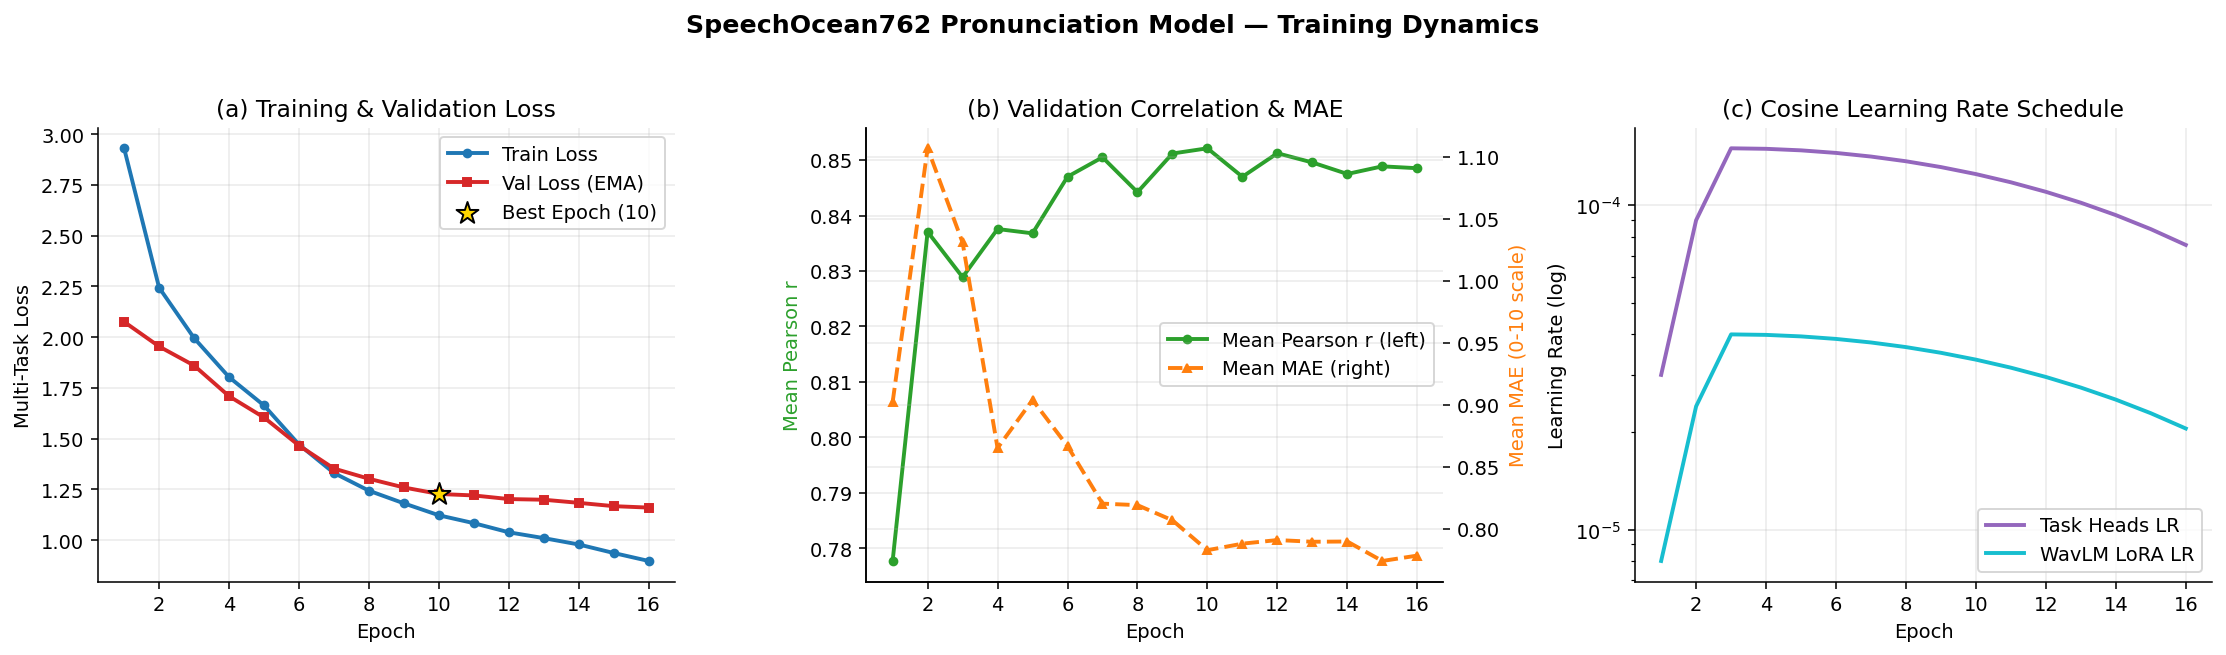

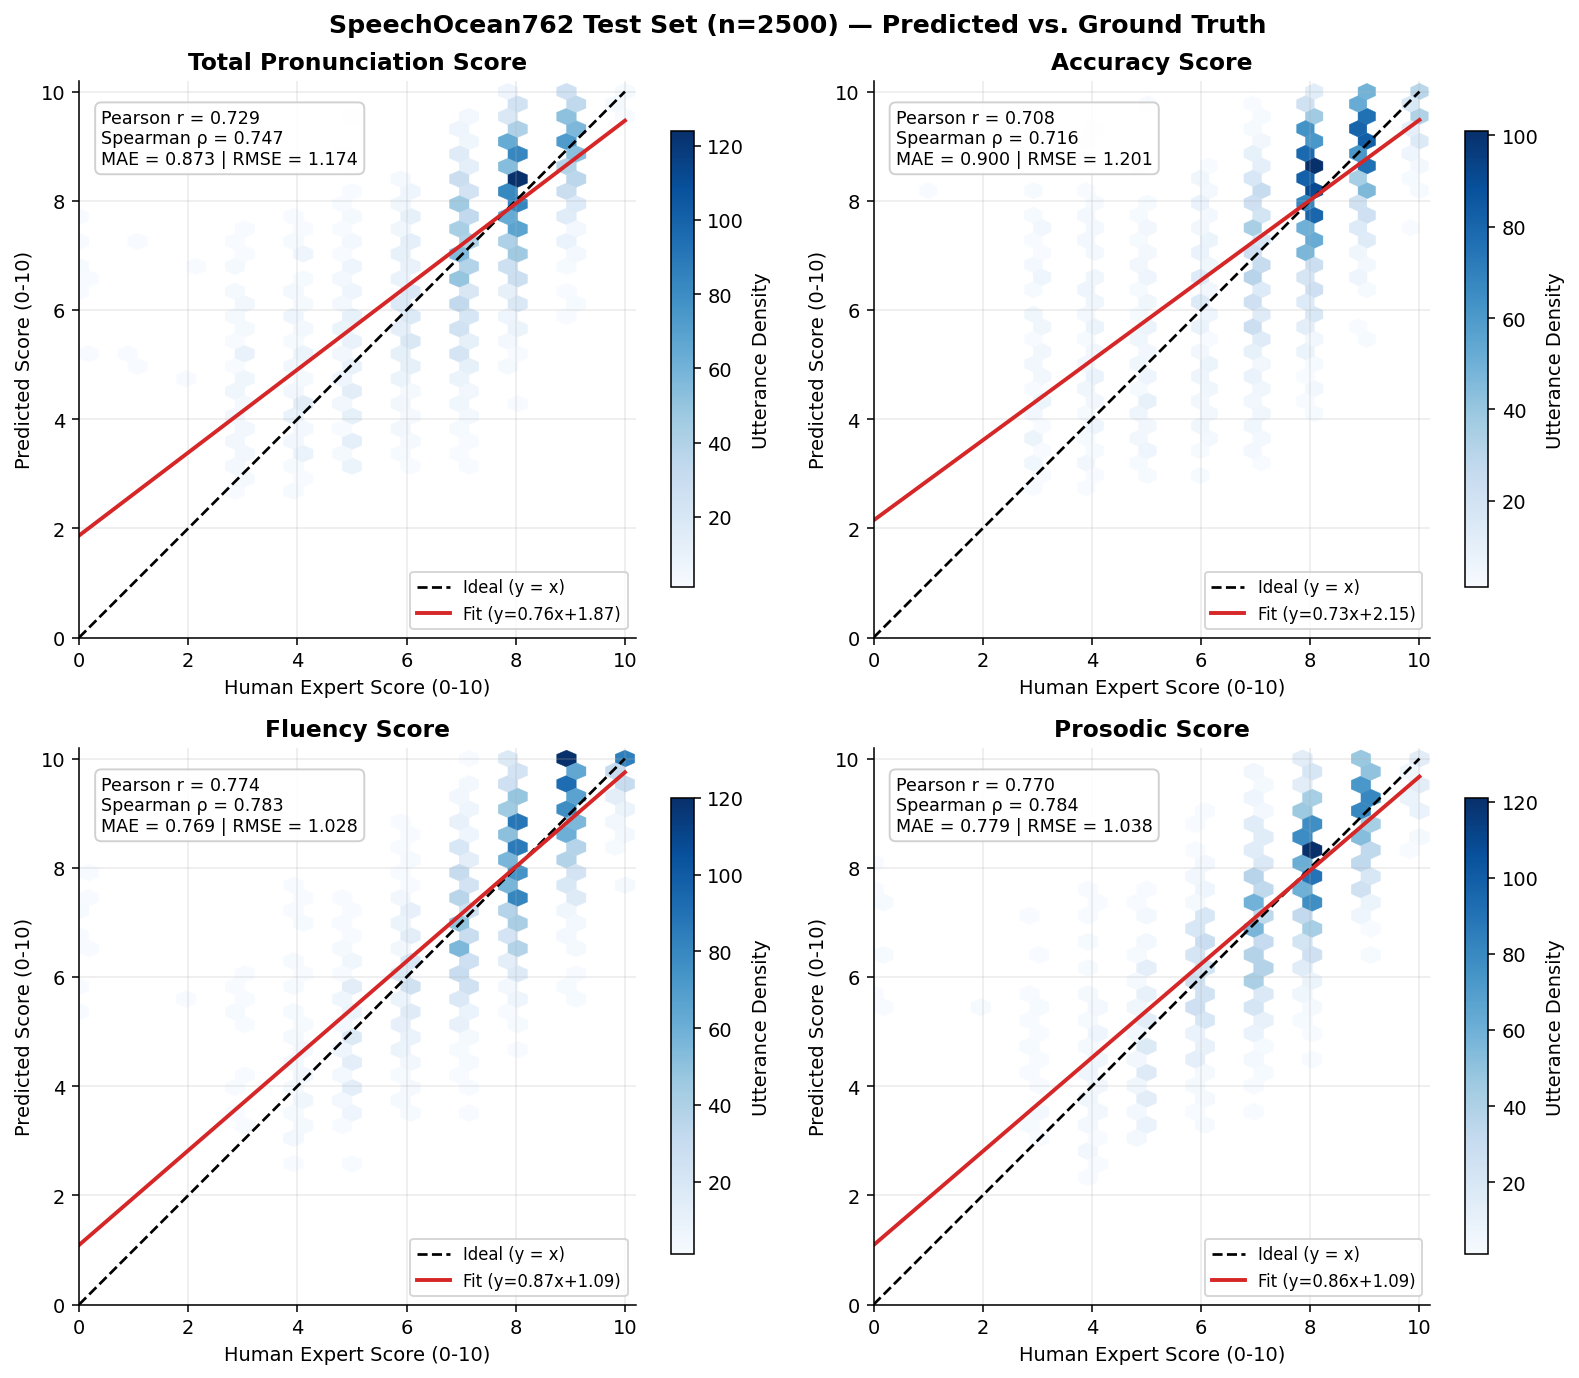

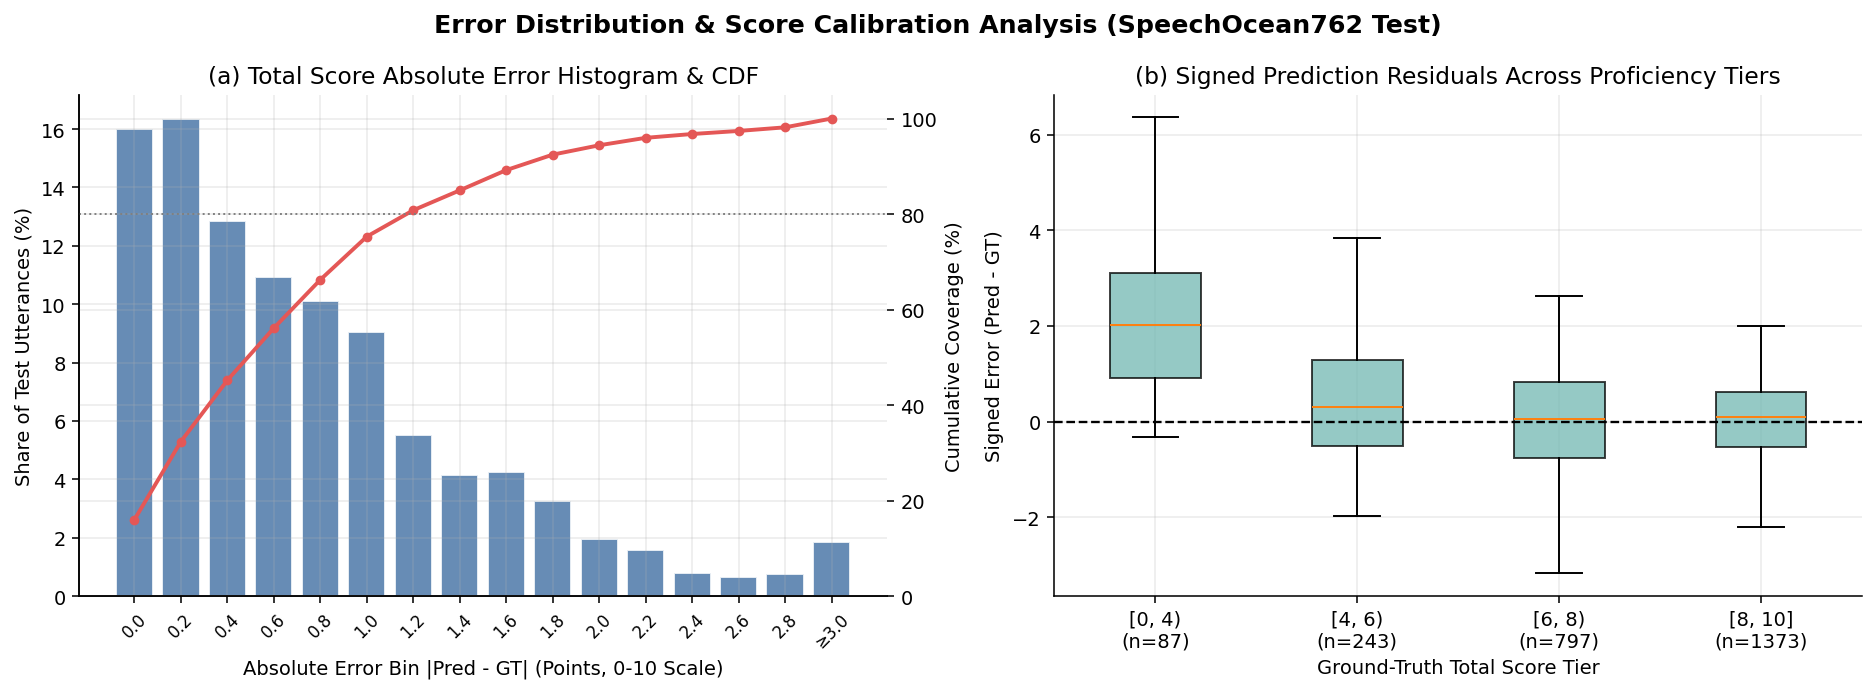

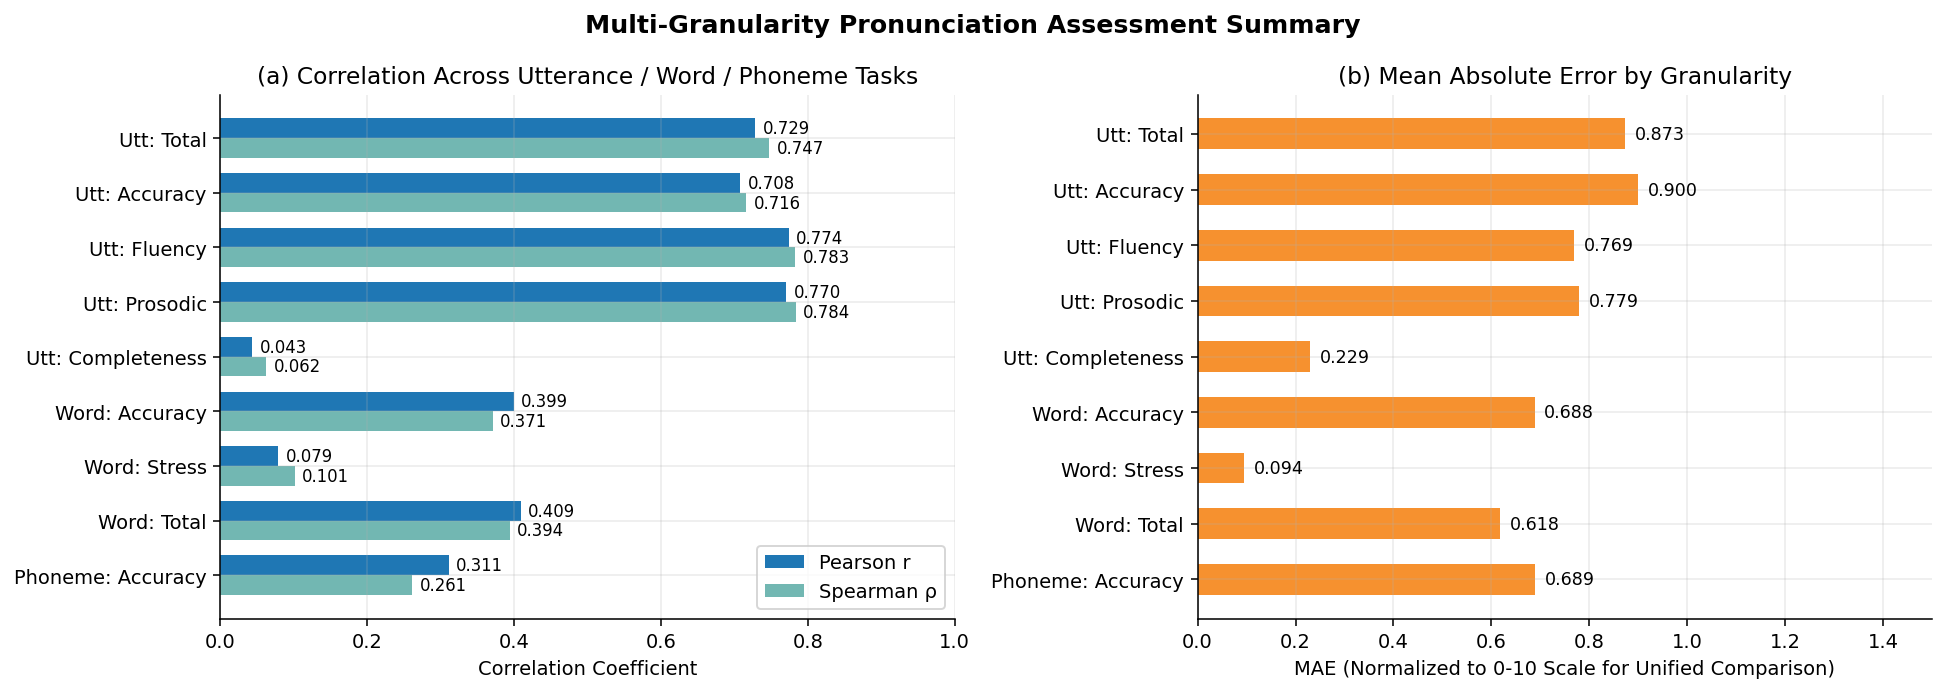


📁 Thesis reports & 300-DPI figures saved to: /kaggle/working/reports_pronunciation

📦 Output files in /kaggle/working:
  - /kaggle/working/__notebook__.ipynb (2.30 MB)
  - /kaggle/working/best_model.pt (1319.81 MB)
  - /kaggle/working/reports_pronunciation/error_distribution_bins.csv (0.00 MB)
  - /kaggle/working/reports_pronunciation/fig1_training_curves_pronunciation.png (0.41 MB)
  - /kaggle/working/reports_pronunciation/fig2_scatter_regression_utterance.png (0.73 MB)
  - /kaggle/working/reports_pronunciation/fig3_error_distribution_and_buckets.png (0.28 MB)
  - /kaggle/working/reports_pronunciation/fig4_multitask_comparison.png (0.32 MB)
  - /kaggle/working/reports_pronunciation/summary_metrics.json (0.00 MB)
  - /kaggle/working/reports_pronunciation/test_predictions_utterance.csv (0.24 MB)
  - /kaggle/working/reports_pronunciation/training_history.csv (0.00 MB)
  - /kaggle/working/reports_pronunciation/utterance_metrics.csv (0.00 MB)
  - /kaggle/working/reports_pronunciation/word

In [5]:
import os, torch
from pathlib import Path

os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")
os.makedirs("/kaggle/working/hf_cache", exist_ok=True)
os.environ["HF_HOME"] = "/kaggle/working/hf_cache"

assert torch.cuda.is_available(), "Settings -> Accelerator -> GPU T4"
torch.cuda.empty_cache()

data_dir = find_speechocean762_dir()
CONFIG["train"]["dataset"]["data_dir"] = str(data_dir)
ok, issues, info = verify_speechocean762(data_dir)
print("Dataset:", info)
if not ok:
    raise RuntimeError("\n".join(issues))

trainer = Trainer(CONFIG)
trainer.train()

print("\n" + "=" * 92)
print("🎯 RUNNING FINAL ISOLATED TEST EVALUATION & GENERATING THESIS CHARTS...")
print("=" * 92)
summary = trainer.evaluate_test_set()

print("\n📦 Output files in /kaggle/working:")
for p in sorted(Path("/kaggle/working").rglob("*")):
    if p.is_file() and "hf_cache" not in str(p):
        print(f"  - {p} ({p.stat().st_size / (1024**2):.2f} MB)")
